# Customer Purchase Behavior Segmentation – Uruguayan Supermarket Chain

Undergraduate thesis notebook (B.Sc. in Data Science for Business, Universidad de Montevideo, 2025).
Authors: Maria Bittencourt, Malena Gómez, Tomás Sanguinetti, Paula Planinich.

> **Note:** the original data belongs to the company and is confidential, so it is not included in this repository.
> Raw data tables, transaction IDs and absolute sales figures were removed from the outputs, and the company name was anonymized.
> The code is shown for reference and will not run without access to the original data.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from gensim.models import Word2Vec
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D
from sklearn.metrics import calinski_harabasz_score
from sklearn.metrics.pairwise import cosine_distances
import matplotlib.ticker as mtick
from sklearn.model_selection import StratifiedShuffleSplit
from tensorflow.keras import layers, models
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import STL
from sklearn.metrics.pairwise import cosine_similarity


df_23 = pd.read_csv("df_2023.csv")

In [ ]:
pd.set_option("display.max_columns", None)
df_23.head(15)

In [ ]:
df_23["TICKET"] = df_23["TICKET"].astype(str)
df_23["SOCI_SOCI_ID"] = df_23["SOCI_SOCI_ID"].astype(str)

In [ ]:
df_23.describe(include="all")

In [ ]:
df_23.shape


(6707608, 23)


In [ ]:
df_xxx = df_23[df_23["GEOG_LOCL_DESC"] == "Hiper Tres Cruces"]
df_xxx.describe(include = "all")

In [ ]:
df_cooper = df_23[df_23["GEOG_LOCL_DESC"] == "Super Cooper"]
df_cooper.describe(include = "all")

In [ ]:
df_21 = df_23[df_23["GEOG_LOCL_DESC"] == "Express 21 de Setiembre"]
df_21.describe(include = "all")

Observamos que los datos faltantes en las columnas de información de clientes son, aproximadamente, parejos en porcentaje.

Vemos los datos faltantes sobre la información de los clientes

In [ ]:
print (df_23["CLIE_CLIE_SEXO"].isnull().sum())
print (df_23["CLIE_CLIE_SEXO"].isnull().sum() / df_23.shape[0])


637297
0.09501106802902018


In [ ]:
print (df_23["SCENTIA_EDAD"].isnull().sum())
print (df_23["SCENTIA_EDAD"].isnull().sum() / df_23.shape[0])


382900
0.057084433079571735


In [ ]:
print (df_23["SCENTIA_NSE"].isnull().sum())
print (df_23["SCENTIA_NSE"].isnull().sum() / df_23.shape[0])


322029
0.0480095139727903


Al ser pocos los datos faltantes en proporción al total, decidimos borrar los registros con datos faltantes, así, cada venta tiene un cliente asignado y, al segmentar, toda venta entrará dentro de un comportamiento de cliente.

In [ ]:
df_23 = df_23.dropna(subset=["CLIE_CLIE_SEXO", "SCENTIA_EDAD", "SCENTIA_NSE"])

In [ ]:
df_23.describe(include="all")

Observamos que la columna de Flag Promo es 0 para todos los registros. La eliminamos ya que no aporta información.

In [ ]:
df_23=df_23.drop(columns=["VNTA_FLAG_PROMO"])

Estudiamos la distribución de los importes de las ventas, primero, con un boxplot, para identificar outliers.

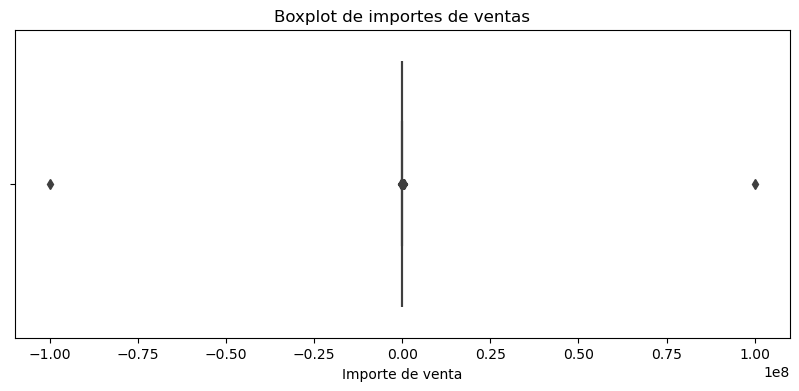

In [ ]:
plt.figure(figsize=(10,4))
sns.boxplot(x=df_23["VNTA_IMPORTE_CON_IVA"])

plt.title("Boxplot de importes de ventas")
plt.xlabel("Importe de venta")
plt.show()

In [ ]:
num_negativos = (df_23["VNTA_IMPORTE_CON_IVA"] < 0).sum()
print(f"Número de importes negativos: {num_negativos}")


Número de importes negativos: 50592


In [ ]:
(df_23["VNTA_IMPORTE_CON_IVA"] < 0).sum() / df_23.shape[0]


0.008386879983502089


Eliminamos los registros negativos asumiendo que se pueden deber a errores, o casos muy particulares de devoluciones que no son determinantes para el análisis del comportamiento de los clientes.

In [ ]:
df_23 = df_23[df_23["VNTA_IMPORTE_CON_IVA"] >= 0]
df_23.describe(include="all")

Estudiamos los outliers, ahora positivos, en los importes de las ventas.

In [ ]:
Q1 = df_23["VNTA_IMPORTE_CON_IVA"].quantile(0.25)
Q3 = df_23["VNTA_IMPORTE_CON_IVA"].quantile(0.75)
IQR = Q3 - Q1

outliers = df_23[(df_23["VNTA_IMPORTE_CON_IVA"] < Q1 - 1.5*IQR) |
              (df_23["VNTA_IMPORTE_CON_IVA"] > Q3 + 1.5*IQR)]

num_outliers = outliers.shape[0]
print(f"Número de outliers: {num_outliers}")
outliers.head(20)


Número de outliers: 328386


In [ ]:
print (Q1, Q3)


40.6 131.0


Observamos que los datos están muy concentrados en valores muy bajos. Estudiamos cuántos de los importes por venta son iguales a 0, y cuántos de estos no son por canjes.

In [ ]:
num_ceros = (df_23["VNTA_IMPORTE_CON_IVA"] == 0).sum()
print(f"Número de importes iguales a 0: {num_ceros}")


Número de importes iguales a 0: 42393


In [ ]:
ventas_0_no_canje = df_23[(df_23["VNTA_IMPORTE_CON_IVA"] == 0) & (df_23["SUB_NAME"] != "CANJES")]
ventas_0_no_canje.head()

In [ ]:
print(ventas_0_no_canje.shape)
print(ventas_0_no_canje.shape[0] / df_23.shape[0])


(33102, 22)
0.005533890355680597


Al ser pocos valores, optamos por eliminarlos, ya que se pueden deber a errores en el proceso de registro del producto, en el proceso de pago, ofertas mal resgistradas, u otras razones poco frecuentes.

In [ ]:
df_23 = df_23[df_23["VNTA_IMPORTE_CON_IVA"] != 0]
df_23.shape


(5939294, 22)


Estudiamos nuevamente los outliers para ver el impacto que tuvo este cambio.

In [ ]:
Q1 = df_23["VNTA_IMPORTE_CON_IVA"].quantile(0.25)
Q3 = df_23["VNTA_IMPORTE_CON_IVA"].quantile(0.75)
IQR = Q3 - Q1

outliers = df_23[(df_23["VNTA_IMPORTE_CON_IVA"] < Q1 - 1.5*IQR) |
              (df_23["VNTA_IMPORTE_CON_IVA"] > Q3 + 1.5*IQR)]

num_outliers = outliers.shape[0]
print(f"Número de outliers: {num_outliers}")
outliers.head(20)


Número de outliers: 326751


In [ ]:
print (Q1, Q3)


42.0 132.0


Observamos que el cambio en los cuartiles y en la cantidad de outliers fue muy pequeño. Observamos que figuran como outliers los casos en los que se vendieron múltiples unidades de productos baratos.

Entendimos que si se compran múltiples unidades del mismo artículo en un mismo ticket, este figura varias veces, de a una unidad y con el precio unitario. Esto puede influenciar en los bajos cuartiles. Estudiamos qué tan frecuentemente se registró la venta como más de una unidad, cuidando no confundir los casos distintos de 1 con las compras en carnicería, fiambrería o panadería por peso.

In [ ]:
ventas_mas_1_unidad = df_23[(df_23["VNTA_UNIDADES"] != 1) & (df_23["VNTA_UNIDADES"] % 1 == 0)]
print(ventas_mas_1_unidad.shape)
ventas_mas_1_unidad.head(20)


(204546, 22)


In [ ]:
ventas_mas_1_unidad.describe(include="all")

In [ ]:
total_unidades_mas_1 = ventas_mas_1_unidad["VNTA_UNIDADES"].sum()
print(f"Total de unidades vendidas (enteros distintos de 1): {total_unidades_mas_1}")


Total de unidades vendidas (enteros distintos de 1): 789479.0


Se vendieron 789479 productos que están registrados como ventas de más de una unidad.

Para ser consistentes con la forma de registro y optimizar el dataset, optamos por sumar las unidades y precios cuando se compra un mismo artículo en un mismo ticket. Para asegurarnos que esta modificación quede bien hecha, sumamos la cantidad total de productos vendidos en el dataset original, que se debe mantener igual luego del cambio. Lógicamente, se reducirán las filas del dataset.

In [ ]:
total_unidades = df_23["VNTA_UNIDADES"].sum()
print(f"Total de unidades vendidas: {total_unidades}")


Total de unidades vendidas: 6079408.296000001


In [ ]:
duplicados = df_23[df_23.duplicated(subset=["TICKET", "ARTC_ARTC_ID"], keep=False)]
unicos = df_23[~df_23.duplicated(subset=["TICKET", "ARTC_ARTC_ID"], keep=False)]

duplicados_agrupados = duplicados.groupby(
    ["TICKET", "ARTC_ARTC_ID"], as_index=False
).agg({
    "TIEM_DIA_ID": "first",
    "HORA_HORA_ID": "first",
    "GEOG_LOCL_COD": "first",
    "GEOG_LOCL_DESC": "first",
    "CLASE": "first",
    "CLASS_NAME": "first",
    "SUBCLASE": "first",
    "SUB_NAME": "first",
    "FOPA_FOPA_ID": "first",
    "FOPA_FOPA_DESC": "first",
    "VNTA_IMPORTE_CON_IVA": "sum",
    "VNTA_UNIDADES": "sum",
    "SOCI_SOCI_ID": "first",
    "CLIE_CLIE_SEXO": "first",
    "SCENTIA_EDAD": "first",
    "SCENTIA_NSE": "first",
    "ARTC_OFN1_ID": "first",
    "ARTC_OFN2_ID": "first",
    "ARTC_OFN3_ID": "first",
    "ARTC_COMB_ID": "first"
})

df_23 = pd.concat([duplicados_agrupados, unicos], ignore_index=True)

df_23 = df_23.sort_values(by=["TICKET", "ARTC_ARTC_ID"]).reset_index(drop=True)

In [ ]:
total_unidades = df_23["VNTA_UNIDADES"].sum()
print(f"Total de unidades vendidas: {total_unidades}")


Total de unidades vendidas: 6079408.296000004


In [ ]:
df_23.head(20)

In [ ]:
df_23.shape


(5205378, 22)


Volvemos a estudiar los outliers, ahora que agrupamos por cantidad de artículos en un mismo ticket.

In [ ]:
Q1 = df_23["VNTA_IMPORTE_CON_IVA"].quantile(0.25)
Q3 = df_23["VNTA_IMPORTE_CON_IVA"].quantile(0.75)
IQR = Q3 - Q1

outliers = df_23[(df_23["VNTA_IMPORTE_CON_IVA"] < Q1 - 1.5*IQR) |
              (df_23["VNTA_IMPORTE_CON_IVA"] > Q3 + 1.5*IQR)]

num_outliers = outliers.shape[0]
print(f"Número de outliers: {num_outliers}")
outliers.head(20)


Número de outliers: 292099


In [ ]:
print (Q1, Q3)


49.0 149.0


Nuevamente se redujeron los outliers, aunque solo en una pequeña cantidad.

Luego, ordenamos los outliers de mayor a menor para detectar lo que realmente fueron valores mal registrados, y diferenciarlos de ventas fuera de lo común pero posibles.

In [ ]:
outliers_ordenados = outliers.sort_values(by="VNTA_IMPORTE_CON_IVA", ascending=False)
outliers_ordenados.head(60)

La venta de los importes mayores a 4000 parecen ser casos muy particulares, ya sea por error en el registro del monto, o por ventas muy específicas.

In [ ]:
porcentaje = ((df_23["VNTA_IMPORTE_CON_IVA"] > 4000).sum()) / len(df_23) * 100
porcentaje


0.006589338949063834


In [ ]:
df_23 = df_23[df_23["VNTA_IMPORTE_CON_IVA"] <= 4000]

Eliminamos los casos en los que el sexo no está correctamente registrado como F o M.

In [ ]:
df_23 = df_23[df_23["CLIE_CLIE_SEXO"] != "0"]

Elminamos los casos en los que la edad es menor a 18.

In [ ]:
df_23 = df_23[df_23["SCENTIA_EDAD"] >= 18]
df_23 = df_23[df_23["SCENTIA_EDAD"] <= 100]

In [ ]:
df_23.shape


(5203794, 22)


In [ ]:
print (df_23["CLIE_CLIE_SEXO"].value_counts())


CLIE_CLIE_SEXO
F    3719033
M    1484761
Name: count, dtype: int64


Haremos unas visualizacinoes de las 20 clases y subclases más compradas (más allá de las cantidades, estudiamos qué necesidades satisfacen las personas en Cadena)

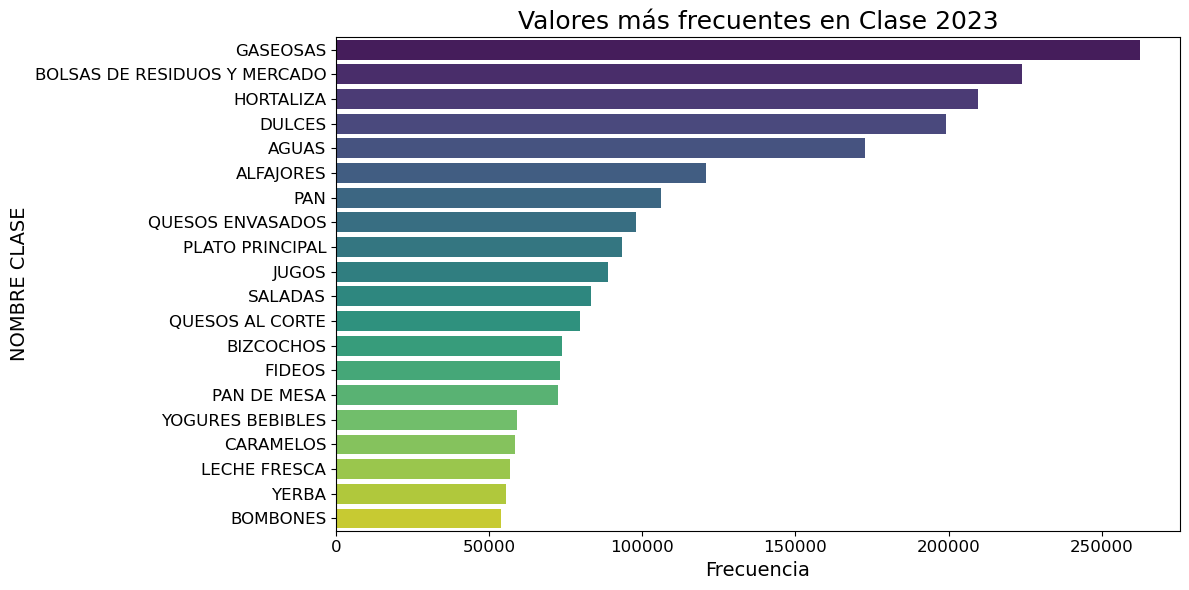

In [ ]:
top_classes = df_23["CLASS_NAME"].value_counts().head(20)

plt.figure(figsize=(12,6))
sns.barplot(x=top_classes.values, y=top_classes.index, palette="viridis")

plt.title("Valores más frecuentes en Clase 2023", fontsize=18)
plt.xlabel("Frecuencia", fontsize = 14)
plt.ylabel("NOMBRE CLASE", fontsize = 14)
plt.xticks(fontsize = 12)
plt.yticks(fontsize = 12)
plt.tight_layout()
plt.show()

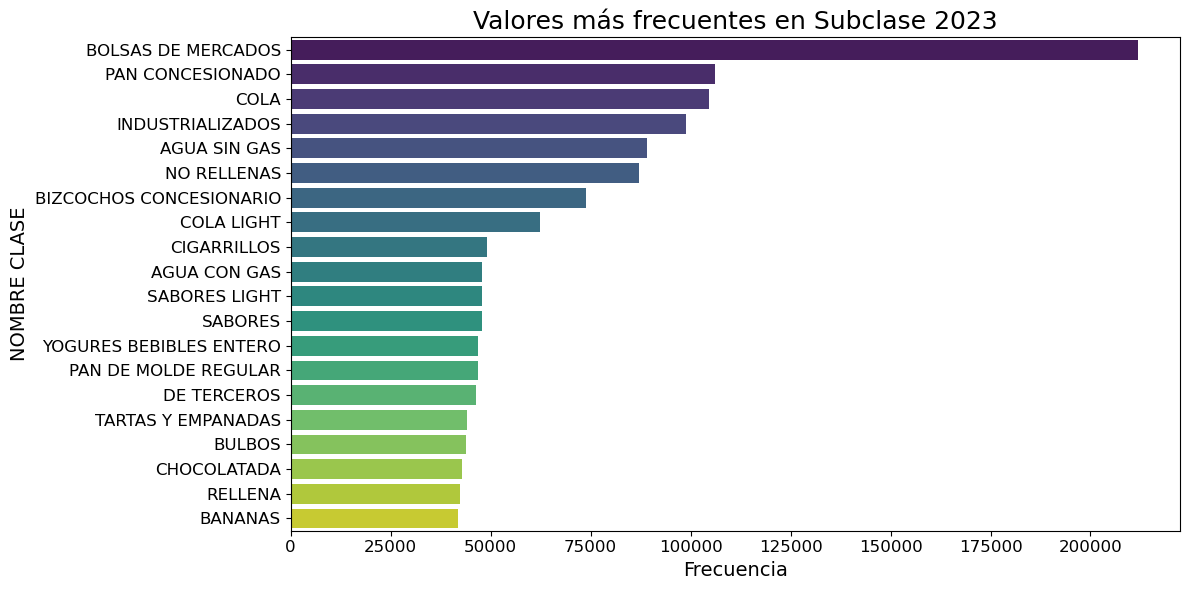

In [ ]:
top_subclasses = df_23["SUB_NAME"].value_counts().head(20)

plt.figure(figsize=(12,6))
sns.barplot(x=top_subclasses.values, y=top_subclasses.index, palette="viridis")

plt.title("Valores más frecuentes en Subclase 2023", fontsize=18)
plt.xlabel("Frecuencia", fontsize = 14)
plt.ylabel("NOMBRE CLASE", fontsize = 14)
plt.xticks(fontsize = 12)
plt.yticks(fontsize = 12)
plt.tight_layout()
plt.show()

Estudiamos también los distintos tipos de formas de pago, y visualizamos los utilizados con mayor frecuencia.

In [ ]:
df_23["FOPA_FOPA_DESC"].value_counts()


FOPA_FOPA_DESC
EFECTIVO                   1347248
VISAELECTRON               1159226
MAESTRO DEBITO              945995
VISA                        260614
OCA                         162576
                            ...   
VISA DEBITO                     21
Maestro                         10
Cadena Card Cuotas                 7
VOUTCHERS MANUALES               3
TARJETA CREDITO VTA WEB          1
Name: count, Length: 61, dtype: int64


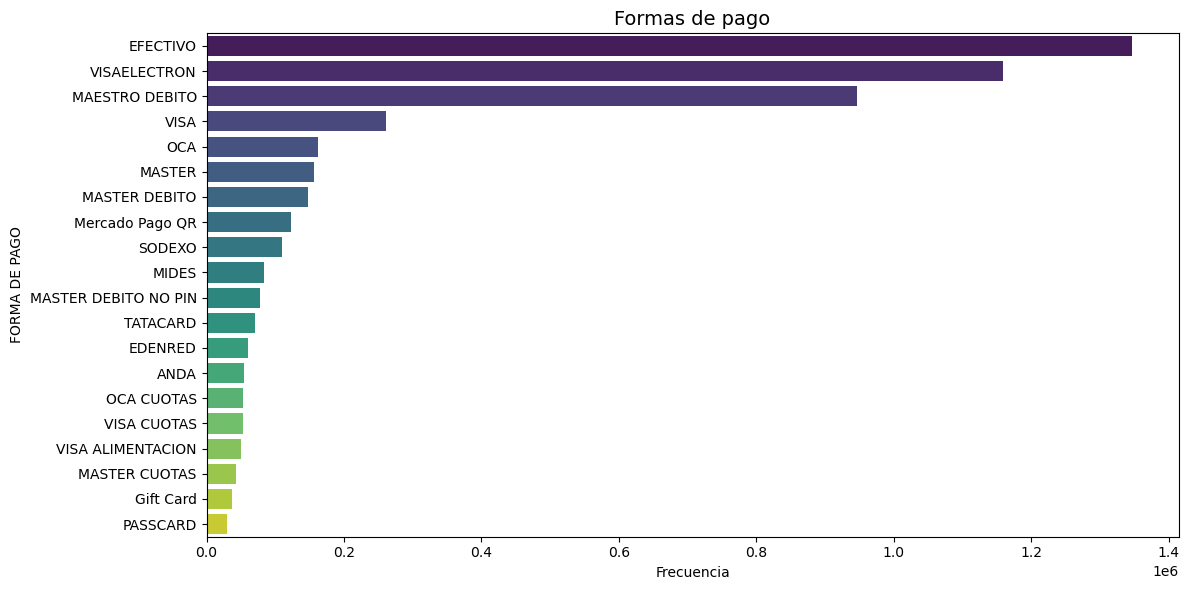

In [ ]:
fopa_fopa = df_23["FOPA_FOPA_DESC"].value_counts().head(20)

plt.figure(figsize=(12,6))
sns.barplot(x=fopa_fopa.values, y=fopa_fopa.index, palette="viridis")

plt.title("Formas de pago", fontsize=14)
plt.xlabel("Frecuencia")
plt.ylabel("FORMA DE PAGO")
plt.tight_layout()
plt.show()

Estudiamos los totales vendidos por mes.

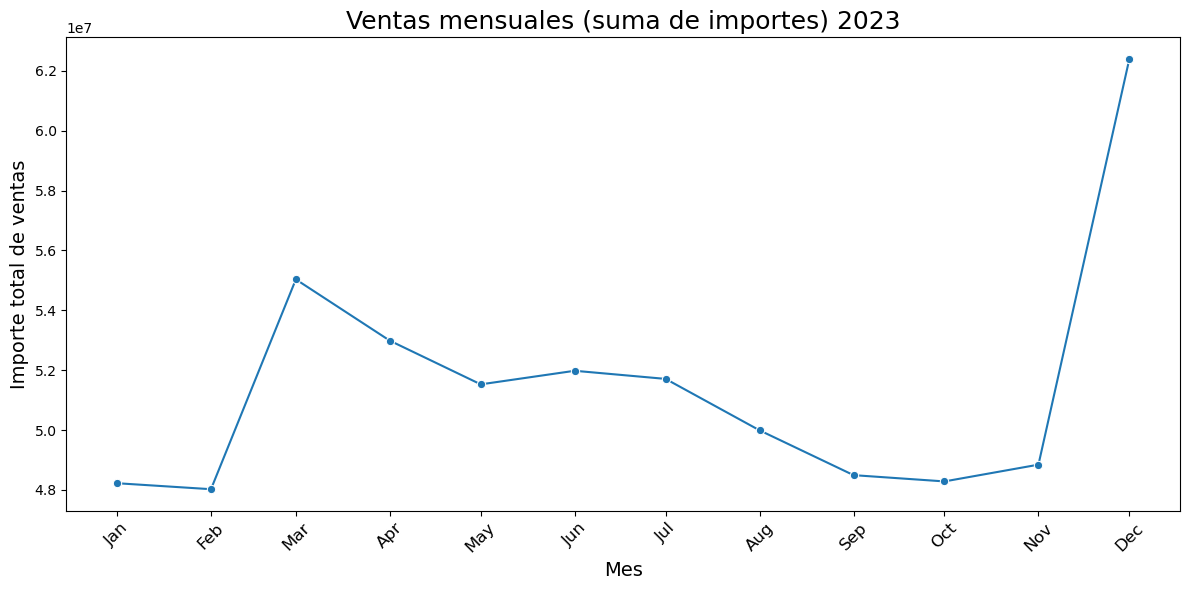

In [ ]:
df_23["FECHA"] = pd.to_datetime(df_23["TIEM_DIA_ID"])

ventas_mensuales = (
    df_23
    .groupby(df_23["FECHA"].dt.to_period("M"))["VNTA_IMPORTE_CON_IVA"]
    .sum()
    .reset_index()
)

ventas_mensuales["FECHA"] = ventas_mensuales["FECHA"].dt.to_timestamp()

todos_los_meses = pd.date_range("2023-01-01", "2023-12-01", freq="MS")
ventas_mensuales = (
    ventas_mensuales
    .set_index("FECHA")
    .reindex(todos_los_meses, fill_value=0)
    .reset_index()
    .rename(columns={"index": "FECHA"})
)

plt.figure(figsize=(12,6))
sns.lineplot(x="FECHA", y="VNTA_IMPORTE_CON_IVA", data=ventas_mensuales, marker="o")
plt.title("Ventas mensuales (suma de importes) 2023", fontsize = 18)
plt.xlabel("Mes", fontsize = 14)
plt.ylabel("Importe total de ventas", fontsize = 14)
plt.xticks(todos_los_meses, todos_los_meses.strftime("%b"), fontsize = 12, rotation=45)
plt.tight_layout()
plt.show()

Estudiamos la cantidad de ventas realizadas por mes.

In [ ]:
df_23["TIEM_DIA_ID"] = pd.to_datetime(df_23["TIEM_DIA_ID"])

tickets_por_mes = (
    df_23.groupby(df_23["TIEM_DIA_ID"].dt.to_period("M"))["TICKET"]
    .nunique()
    .reset_index()
)

tickets_por_mes["TIEM_DIA_ID"] = tickets_por_mes["TIEM_DIA_ID"].dt.to_timestamp()

print(tickets_por_mes)


   TIEM_DIA_ID  TICKET
0   2023-01-01   90586
1   2023-02-01   88088
2   2023-03-01  101178
3   2023-04-01   94003
4   2023-05-01   96785
5   2023-06-01   94868
6   2023-07-01   97311
7   2023-08-01   96408
8   2023-09-01   92860
9   2023-10-01   95939
10  2023-11-01   95460
11  2023-12-01  107797


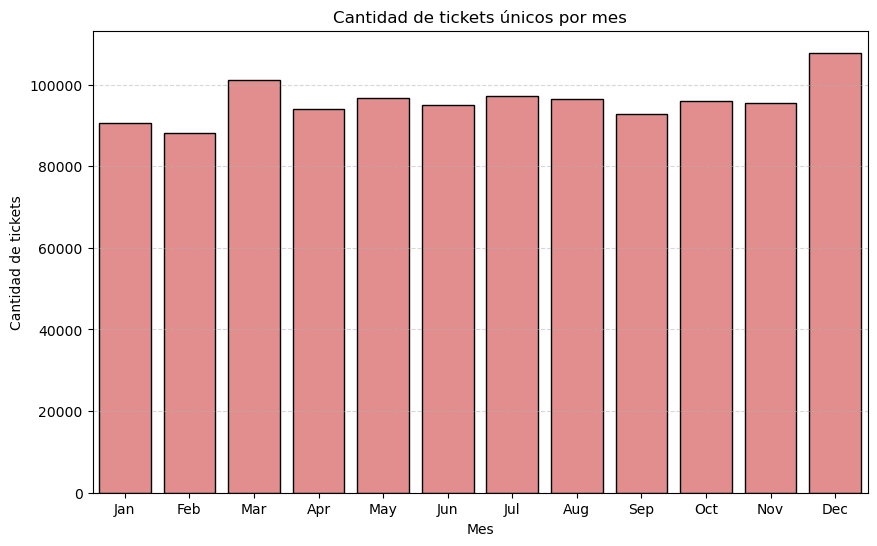

In [ ]:
tickets_por_mes["MES"] = tickets_por_mes["TIEM_DIA_ID"].dt.strftime("%b")

plt.figure(figsize=(10,6))
sns.barplot(x="MES", y="TICKET", data=tickets_por_mes, color="lightcoral", edgecolor="black")

plt.title("Cantidad de tickets únicos por mes")
plt.xlabel("Mes")
plt.ylabel("Cantidad de tickets")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

Estudiamos el promedio del ticket según el mes.

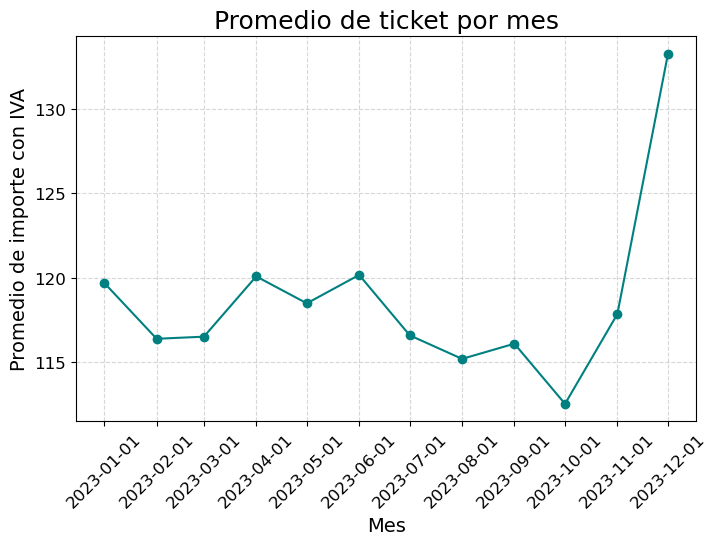

In [ ]:
promedio_mes = (
    df_23
    .groupby(df_23["TIEM_DIA_ID"].dt.to_period("M"))["VNTA_IMPORTE_CON_IVA"]
    .mean()
    .reindex(pd.period_range(df_23["TIEM_DIA_ID"].dt.to_period("M").min(),
                             df_23["TIEM_DIA_ID"].dt.to_period("M").max()), fill_value=0)
)

plt.figure(figsize=(8,5))
promedio_mes.index = promedio_mes.index.to_timestamp()  # Para que matplotlib lo entienda como fechas
plt.plot(promedio_mes.index, promedio_mes.values, marker="o", linestyle="-", color="teal")

plt.title("Promedio de ticket por mes", fontsize = 18)
plt.xlabel("Mes", fontsize = 14)
plt.ylabel("Promedio de importe con IVA", fontsize = 14)
plt.xticks(pd.date_range(promedio_mes.index.min(), promedio_mes.index.max(), freq="MS"), fontsize = 12, rotation=45)
plt.yticks(fontsize = 12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

Estudiamos la cantidad de productos comprados por mujeres y por hombres.

In [ ]:
df_23["CLIE_CLIE_SEXO"] = df_23["CLIE_CLIE_SEXO"].map({"F": 0, "M": 1})

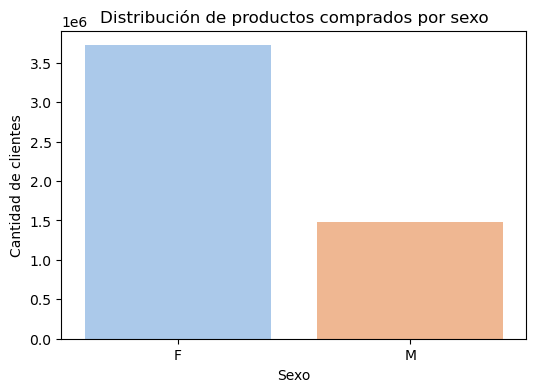

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(
    x="CLIE_CLIE_SEXO",
    data=df_23,
    palette="pastel",
    order=[0, 1]
)

plt.xticks([0, 1], ["F", "M"])

plt.title("Distribución de productos comprados por sexo")
plt.xlabel("Sexo")
plt.ylabel("Cantidad de clientes")
plt.show()

In [ ]:
df_23.head()

In [ ]:
df_23["CLIE_CLIE_SEXO"].value_counts()


CLIE_CLIE_SEXO
0    3719033
1    1484761
Name: count, dtype: int64


Comparamos la distribución de los importes realizados por cada sexo.

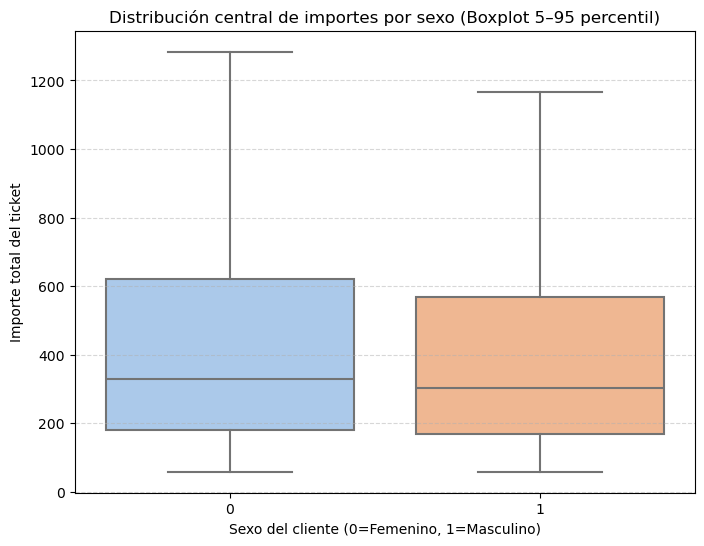

In [ ]:
tickets_sexo = (
    df_23
    .groupby(["TICKET", "CLIE_CLIE_SEXO"])["VNTA_IMPORTE_CON_IVA"]
    .sum()
    .reset_index()
)

lim_inf = tickets_sexo["VNTA_IMPORTE_CON_IVA"].quantile(0.05)
lim_sup = tickets_sexo["VNTA_IMPORTE_CON_IVA"].quantile(0.95)

tickets_sexo_lim = tickets_sexo[
    (tickets_sexo["VNTA_IMPORTE_CON_IVA"] >= lim_inf) &
    (tickets_sexo["VNTA_IMPORTE_CON_IVA"] <= lim_sup)
]

plt.figure(figsize=(8,6))
sns.boxplot(
    x="CLIE_CLIE_SEXO",
    y="VNTA_IMPORTE_CON_IVA",
    data=tickets_sexo_lim,
    palette="pastel",
    showfliers=False  # Esta línea elimina los outliers
)

plt.title("Distribución central de importes por sexo (Boxplot 5–95 percentil)")
plt.xlabel("Sexo del cliente (0=Femenino, 1=Masculino)")
plt.ylabel("Importe total del ticket")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

Estudiamos la distribución de la edad de los clientes.

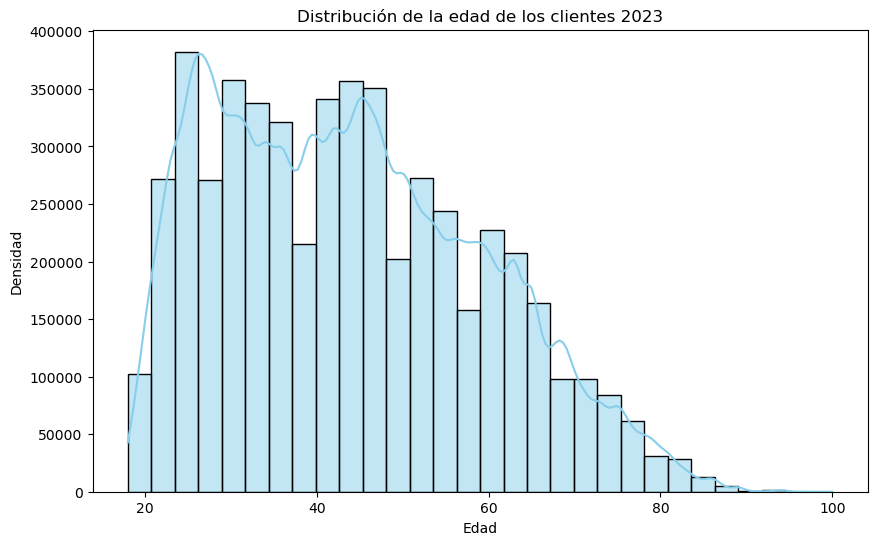

In [ ]:
plt.figure(figsize=(10,6))
sns.histplot(df_23["SCENTIA_EDAD"], bins=30, kde=True, color="skyblue")

plt.title("Distribución de la edad de los clientes 2023")
plt.xlabel("Edad")
plt.ylabel("Densidad")
plt.show()

Estudiamos la distribución de los niveles socioeconómicos en productos comprados.

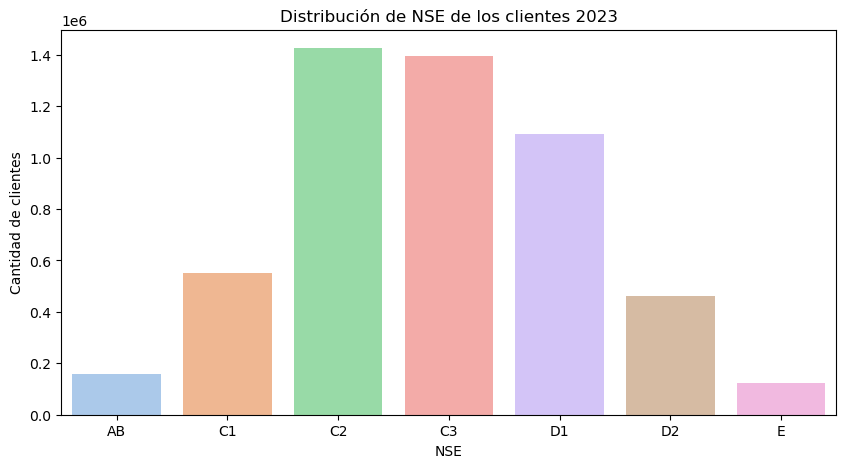

In [ ]:
orden_nse = ["AB", "C1", "C2", "C3", "D1", "D2", "E"]

plt.figure(figsize=(10,5))
sns.countplot(x="SCENTIA_NSE", data=df_23, order=orden_nse, palette="pastel")

plt.title("Distribución de NSE de los clientes 2023")
plt.xlabel("NSE")
plt.ylabel("Cantidad de clientes")
plt.show()

Estudiamos la distribución del total de los importes de los tickets según el nivel socioeconómico.

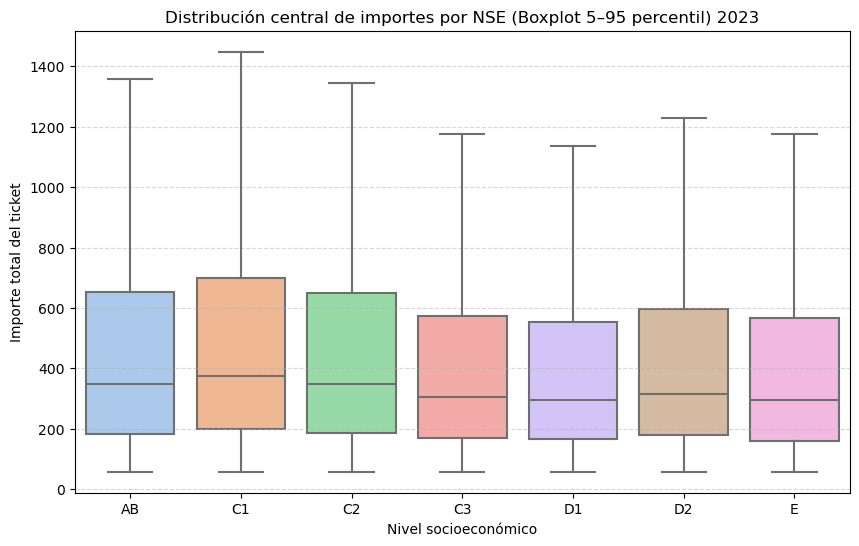

In [ ]:
tickets_totales = (
    df_23
    .groupby(["TICKET", "SCENTIA_NSE"])["VNTA_IMPORTE_CON_IVA"]
    .sum()
    .reset_index()
)

lim_inf = tickets_totales["VNTA_IMPORTE_CON_IVA"].quantile(0.05)
lim_sup = tickets_totales["VNTA_IMPORTE_CON_IVA"].quantile(0.95)
tickets_lim = tickets_totales[
    (tickets_totales["VNTA_IMPORTE_CON_IVA"] >= lim_inf) &
    (tickets_totales["VNTA_IMPORTE_CON_IVA"] <= lim_sup)
]

orden_nse = ["AB", "C1", "C2", "C3", "D1", "D2", "E"]

plt.figure(figsize=(10,6))
sns.boxplot(
    x="SCENTIA_NSE",
    y="VNTA_IMPORTE_CON_IVA",
    data=tickets_lim,
    order=orden_nse,
    palette="pastel",
    showfliers=False
)

plt.title("Distribución central de importes por NSE (Boxplot 5–95 percentil) 2023")
plt.xlabel("Nivel socioeconómico")
plt.ylabel("Importe total del ticket")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

Estudiamos la distribución de la cantidad de tickets comprados por nivel socioeconómico.

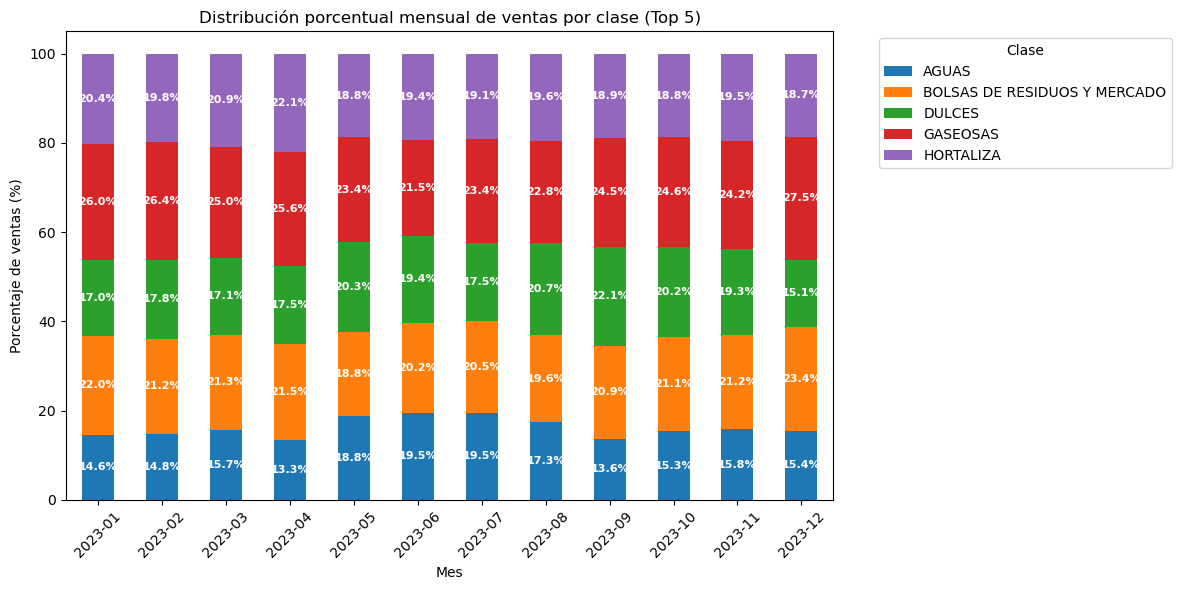

In [ ]:
df_23["MES"] = df_23["TIEM_DIA_ID"].dt.to_period("M")

clase_mes = (
    df_23.groupby(["MES", "CLASE", "CLASS_NAME"])
    .size()
    .reset_index(name="VENTAS")
)

# Top 5 clases mes a mes
top_clases_mes = (
    clase_mes.sort_values(["MES", "VENTAS"], ascending=[True, False])
    .groupby("MES")
    .head(5)
)

subclase_mes = (
    df_23.groupby(["MES", "CLASE", "SUBCLASE", "SUB_NAME"])
    .size()
    .reset_index(name="VENTAS")
)

top_subclases_mes = (
    subclase_mes.sort_values(["MES", "VENTAS"], ascending=[True, False])
    .groupby("MES")
    .head(5)
)

top5_clases = (
    clase_mes.groupby("CLASE")["VENTAS"].sum()
    .sort_values(ascending=False)
    .head(5)
    .index
)

clases_top5 = clase_mes[clase_mes["CLASE"].isin(top5_clases)]

pivot_clases = clases_top5.pivot(index="MES", columns="CLASS_NAME", values="VENTAS")

pivot_clases_percent = pivot_clases.div(pivot_clases.sum(axis=1), axis=0) * 100

ax = pivot_clases_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(12,6)
)

plt.title("Distribución porcentual mensual de ventas por clase (Top 5)")
plt.ylabel("Porcentaje de ventas (%)")
plt.xlabel("Mes")
plt.legend(title="Clase", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)

for container in ax.containers:
    ax.bar_label(container, labels=[f'{val:.1f}%' if val > 5 else '' for val in container.datavalues], 
                 label_type='center', fontsize=8, color='white', weight='bold')

plt.tight_layout()
plt.show()

In [ ]:
df_xxx = df_23[df_23["GEOG_LOCL_DESC"] == "Hiper Tres Cruces"]
df_cooper = df_23[df_23["GEOG_LOCL_DESC"] == "Super Cooper"]
df_21 = df_23[df_23["GEOG_LOCL_DESC"] == "Express 21 de Setiembre"]

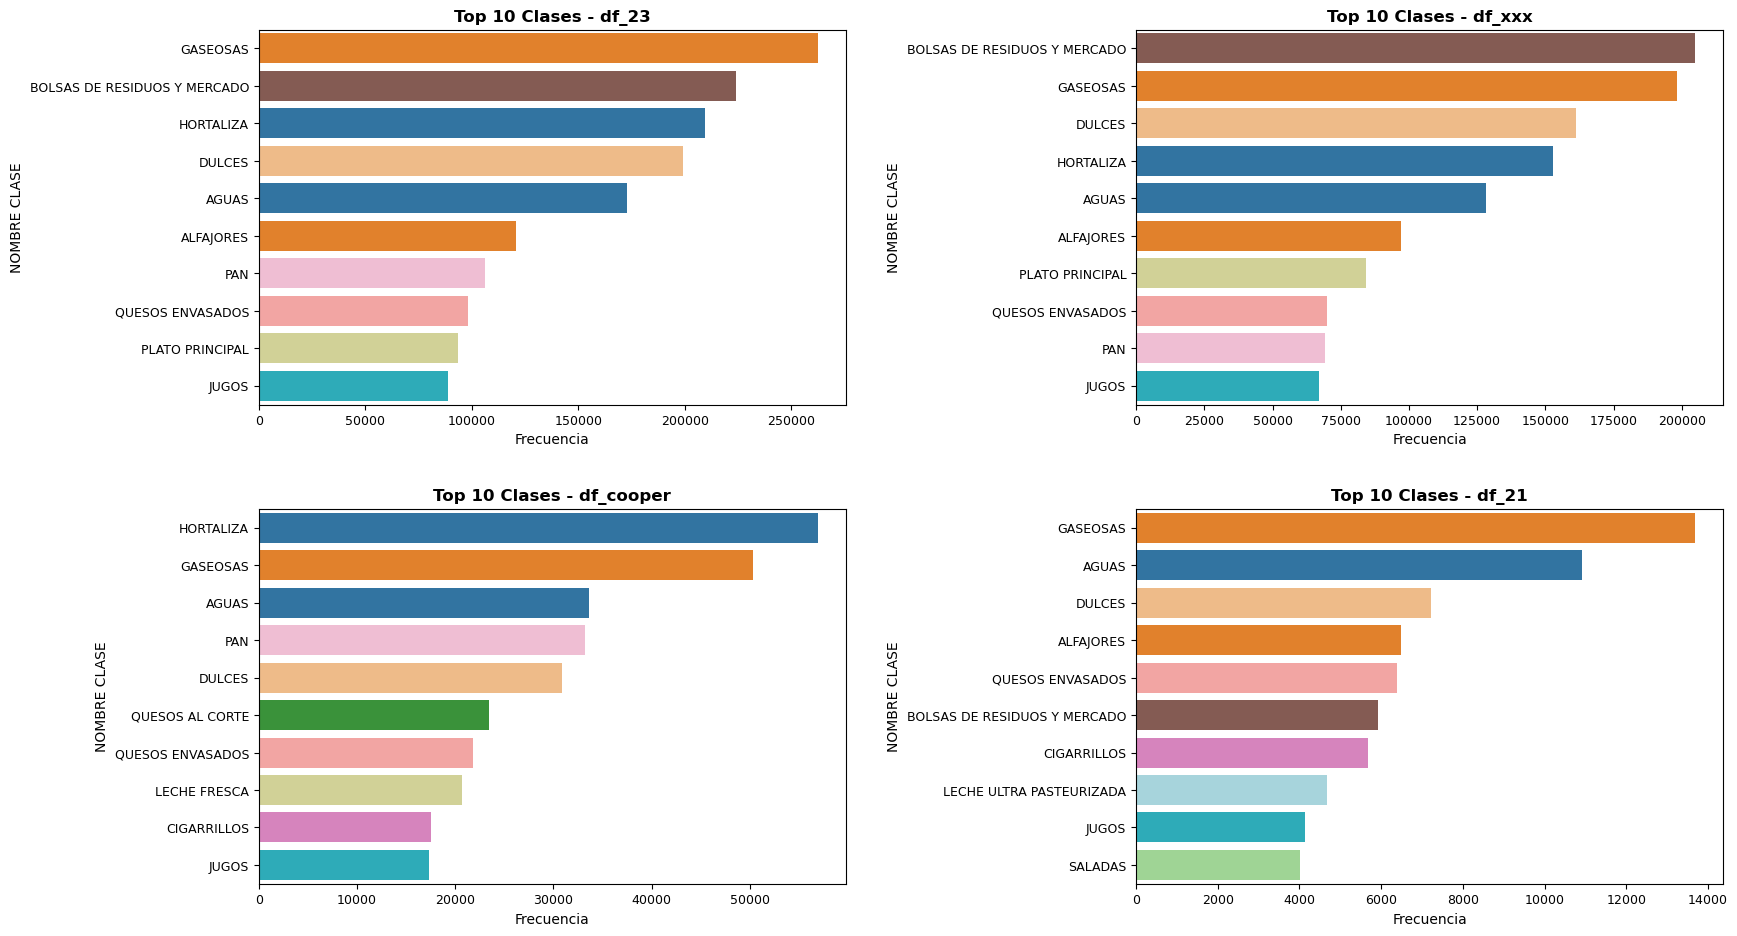

In [ ]:
plt.style.use('default')

todos_los_df = pd.concat([df_23, df_xxx, df_cooper, df_21])
todas_las_clases = todos_los_df["CLASS_NAME"].unique()

palette = sns.color_palette("tab20", len(todas_las_clases))
color_map = {clase: palette[i] for i, clase in enumerate(todas_las_clases)}

fig, axes = plt.subplots(2, 2, figsize=(18, 10))
axes = axes.flatten()

dataframes = {
    "df_23": df_23,
    "df_xxx": df_xxx, 
    "df_cooper": df_cooper,
    "df_21": df_21
}

for i, (nombre, df) in enumerate(dataframes.items()):
    top_classes = df["CLASS_NAME"].value_counts().head(10)

    colors = [color_map[clase] for clase in top_classes.index]

    sns.barplot(
        x=top_classes.values,
        y=top_classes.index,
        ax=axes[i],
        palette=colors
    )

    axes[i].set_title(f'Top 10 Clases - {nombre}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Frecuencia', fontsize=10)
    axes[i].set_ylabel('NOMBRE CLASE', fontsize=10)
    axes[i].tick_params(axis='y', labelsize=9)
    axes[i].tick_params(axis='x', labelsize=9)

plt.tight_layout(pad=3.0)
plt.show()

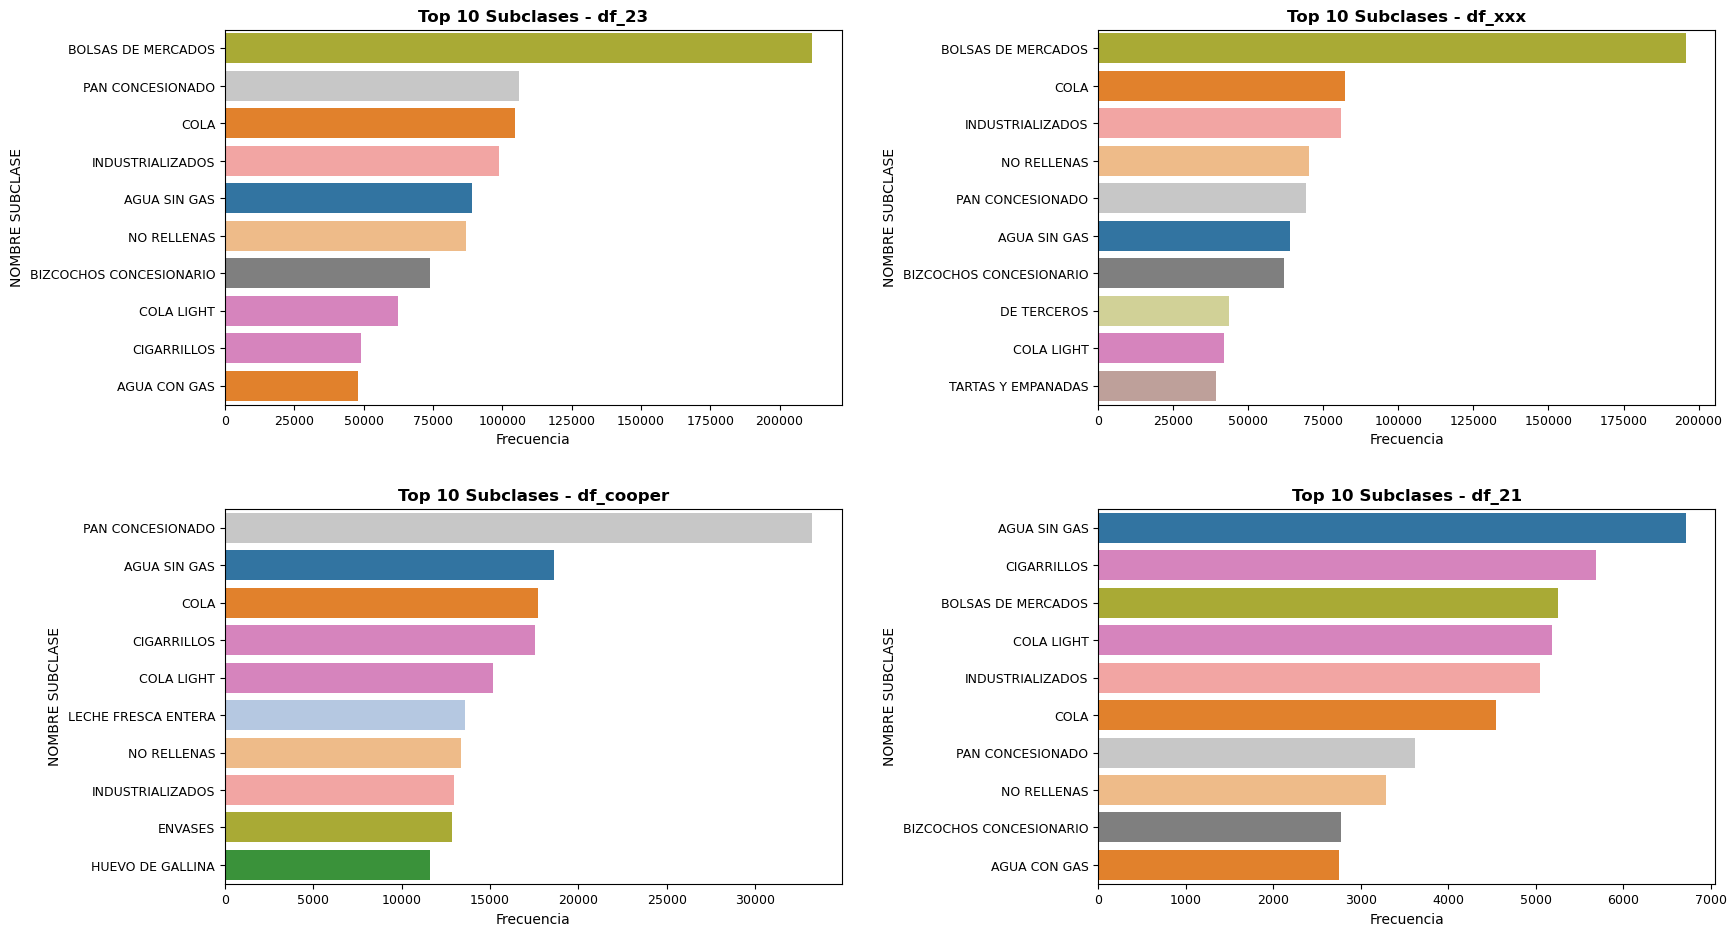

In [ ]:
plt.style.use('default')

todos_los_df = pd.concat([df_23, df_xxx, df_cooper, df_21])
todas_las_clases = todos_los_df["SUB_NAME"].unique()

palette = sns.color_palette("tab20", len(todas_las_clases))
color_map = {clase: palette[i] for i, clase in enumerate(todas_las_clases)}

fig, axes = plt.subplots(2, 2, figsize=(18, 10))
axes = axes.flatten()

dataframes = {
    "df_23": df_23,
    "df_xxx": df_xxx, 
    "df_cooper": df_cooper,
    "df_21": df_21
}

for i, (nombre, df) in enumerate(dataframes.items()):
    top_classes = df["SUB_NAME"].value_counts().head(10)

    colors = [color_map[clase] for clase in top_classes.index]

    sns.barplot(
        x=top_classes.values,
        y=top_classes.index,
        ax=axes[i],
        palette=colors
    )

    axes[i].set_title(f'Top 10 Subclases - {nombre}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Frecuencia', fontsize=10)
    axes[i].set_ylabel('NOMBRE SUBCLASE', fontsize=10)
    axes[i].tick_params(axis='y', labelsize=9)
    axes[i].tick_params(axis='x', labelsize=9)

plt.tight_layout(pad=3.0)
plt.show()

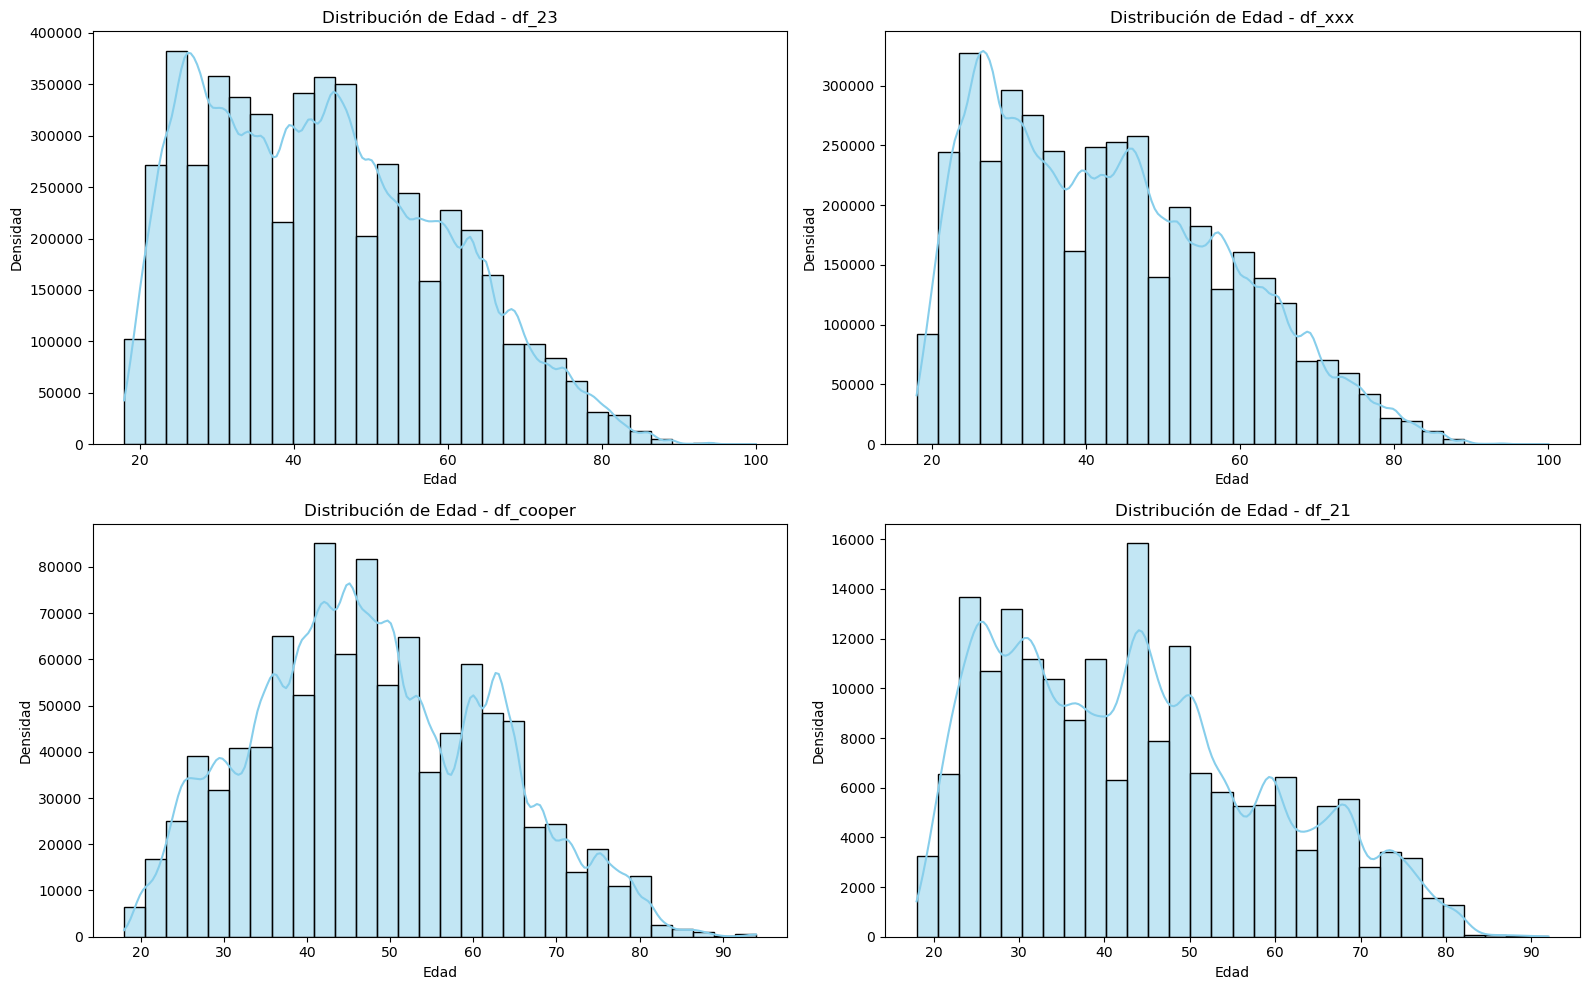

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

dataframes = {
    "df_23": df_23,
    "df_xxx": df_xxx, 
    "df_cooper": df_cooper,
    "df_21": df_21
}

for i, (nombre, df) in enumerate(dataframes.items()):
    sns.histplot(df["SCENTIA_EDAD"], bins=30, kde=True, color="skyblue", ax=axes[i])
    axes[i].set_title(f"Distribución de Edad - {nombre}")
    axes[i].set_xlabel("Edad")
    axes[i].set_ylabel("Densidad")

plt.tight_layout()
plt.show()

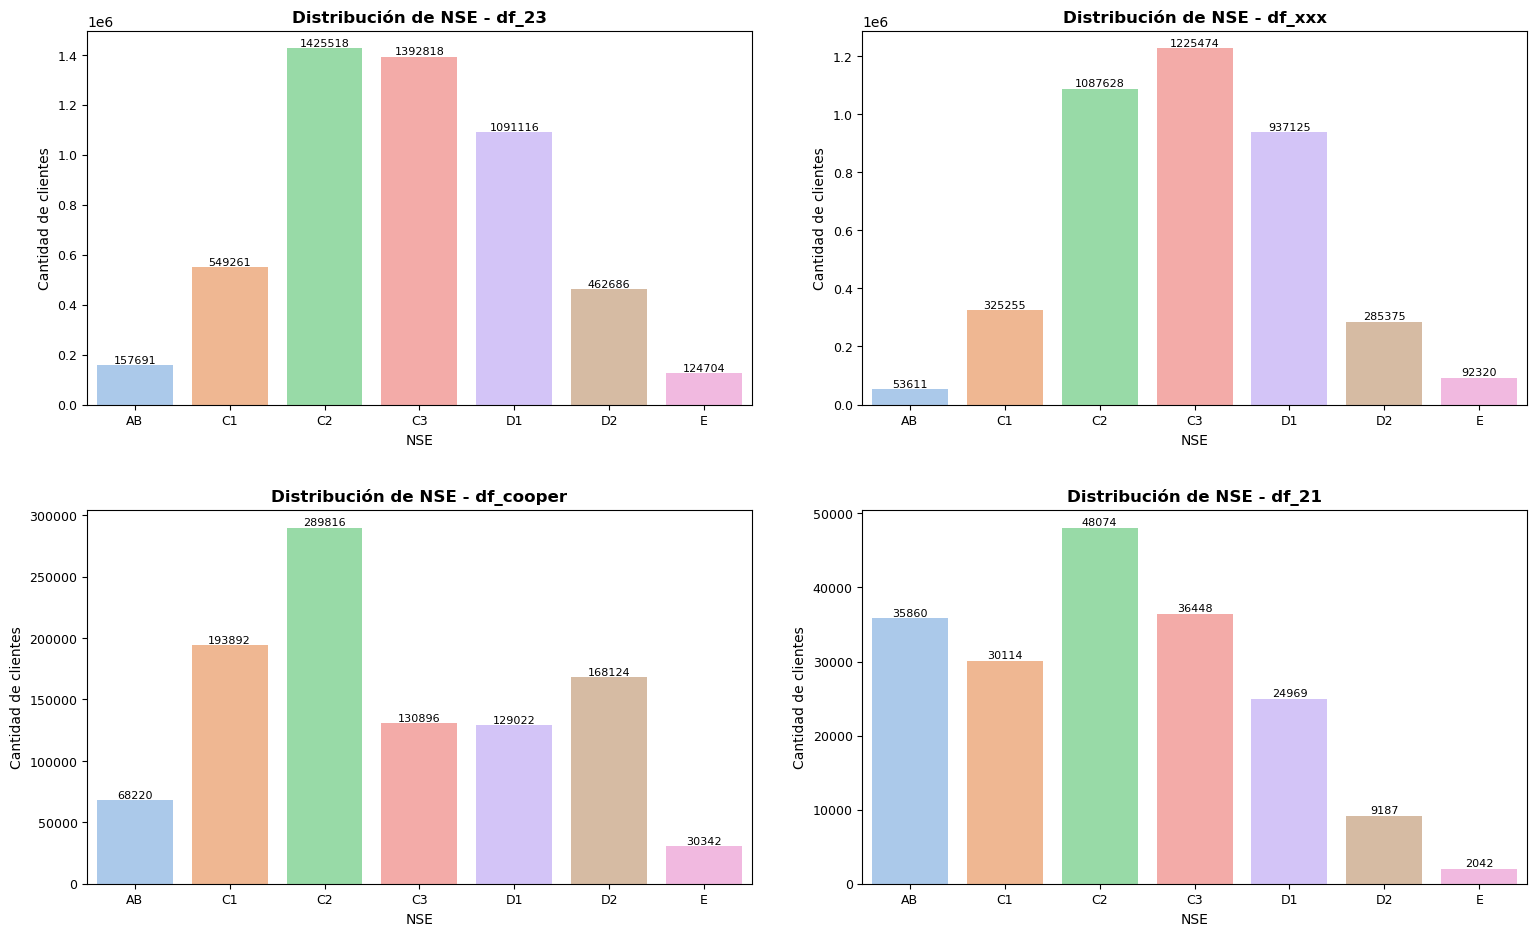

In [ ]:
plt.style.use('default')

orden_nse = ["AB", "C1", "C2", "C3", "D1", "D2", "E"]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

dataframes = {
    "df_23": df_23,
    "df_xxx": df_xxx, 
    "df_cooper": df_cooper,
    "df_21": df_21
}

for i, (nombre, df) in enumerate(dataframes.items()):
    sns.countplot(x="SCENTIA_NSE", data=df, order=orden_nse, palette="pastel", ax=axes[i])
    
    axes[i].set_title(f'Distribución de NSE - {nombre}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('NSE', fontsize=10)
    axes[i].set_ylabel('Cantidad de clientes', fontsize=10)
    
    axes[i].tick_params(axis='both', labelsize=9)
    
    for p in axes[i].patches:
        axes[i].annotate(f'{p.get_height():.0f}', 
                        (p.get_x() + p.get_width() / 2., p.get_height()), 
                        ha='center', va='bottom', fontsize=8)

plt.tight_layout(pad=3.0)
plt.show()

# ANÁLISIS DE RUIDO

In [ ]:
n_tickets = df_23["TICKET"].nunique()

n_clases = df_23["SUBCLASE"].nunique()

total_celdas = n_tickets * n_clases

no_ceros = df_23[["TICKET", "SUBCLASE"]].drop_duplicates().shape[0]

sparsity = (1 - no_ceros / total_celdas) * 100

print("Total de celdas:", total_celdas)
print("Celdas no cero:", no_ceros)
print(f"Sparsity: {sparsity:.4f}%")


Total de celdas: 1743042462
Celdas no cero: 4929466
Sparsity: 99.7172%


# WORD2VEC + KMEANS

In [ ]:
# Convertir los IDs a string
df_23['ARTC_ARTC_ID'] = df_23['ARTC_ARTC_ID'].astype(str)

# Agrupar los artículos por ticket
tickets = (
    df_23.groupby('TICKET')['ARTC_ARTC_ID']
    .apply(list)
    .tolist()
)

In [ ]:
df_23.groupby('TICKET')['ARTC_ARTC_ID'].count().mean()


4.519995518043783


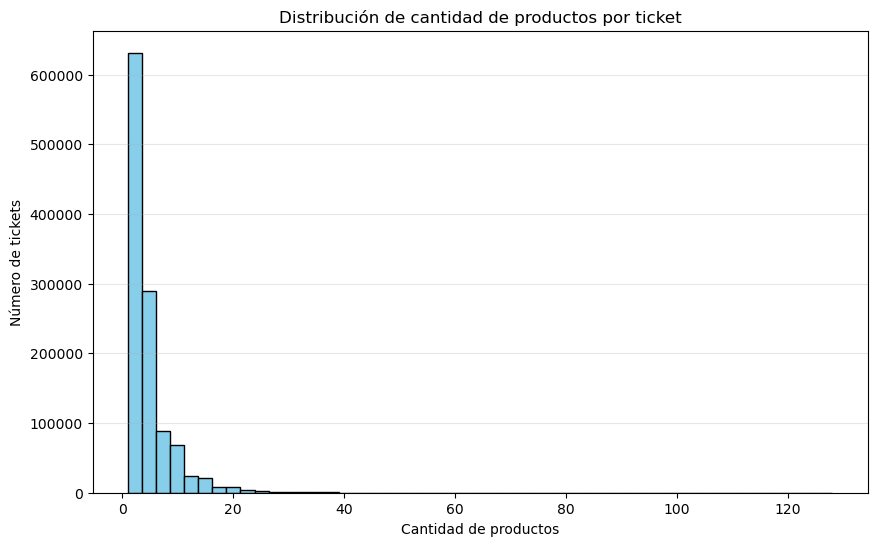

In [ ]:
productos_por_ticket = df_23.groupby('TICKET')['ARTC_ARTC_ID'].count()

plt.figure(figsize=(10,6))
plt.hist(productos_por_ticket, bins=50, color='skyblue', edgecolor='black')
plt.title('Distribución de cantidad de productos por ticket')
plt.xlabel('Cantidad de productos')
plt.ylabel('Número de tickets')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [ ]:
# 2) Entrenar el modelo Word2Vec

w2v_size = 128       # dimensión del embedding
w2v_window = 40      # contexto: cuántos artículos cercanos usa
w2v_min_count = 1    # ignora artículos con pocas apariciones
w2v_workers = 4      # núm. de hilos paralelos

w2v_model = Word2Vec(
    sentences=tickets,
    vector_size=w2v_size,
    window=w2v_window,
    min_count=w2v_min_count,
    sg=1,
    workers=w2v_workers,
    epochs=10
)

In [ ]:
# 3) Crear embeddings por ticket

ticket_vecs = []
ticket_ids = []

for t_id, items in df_23.groupby('TICKET')['ARTC_ARTC_ID']:
    # Tomar embeddings solo de los artículos que el modelo conoce
    valid_vecs = [w2v_model.wv[i] for i in items if i in w2v_model.wv]
    if len(valid_vecs) > 0:
        # Promedio de los embeddings de los artículos del ticket
        ticket_vec = np.mean(valid_vecs, axis=0)
        ticket_vecs.append(ticket_vec)
        ticket_ids.append(t_id)

embeddings = np.vstack(ticket_vecs)

In [ ]:
# 4) Estandarizar los embeddings

scaler = StandardScaler()
embeddings_scaled = scaler.fit_transform(embeddings)

In [ ]:
productos_existentes = list(w2v_model.wv.index_to_key)
len(productos_existentes), productos_existentes[:20]


(20586,
 ['210242',
  '109435',
  '18456',
  '162518',
  '102125',
  '68374',
  '102592',
  '102126',
  '162527',
  '162519',
  '70069',
  '22015',
  '75878',
  '239855',
  '25960',
  '23002',
  '23519',
  '23072',
  '180658',
  '86264'])


In [ ]:
lista_ids = [
 '210242','109435','18456','162518','102125','68374','102592','102126',
 '162527','162519','70069','22015','75878','239855','25960','23002',
 '23519','23072','180658','86264'
]
df_23[df_23['ARTC_ARTC_ID'].isin(lista_ids)][[
    'ARTC_ARTC_ID', 'CLASS_NAME', 'SUB_NAME'
]].drop_duplicates()

In [ ]:
producto = "70069"
vec_ref = w2v_model.wv[producto].reshape(1, -1)

# Obtener listas de productos y sus vectores
productos = list(w2v_model.wv.index_to_key)
matriz_vecs = w2v_model.wv[productos]

# Similaridad con todos los productos
sims = cosine_similarity(vec_ref, matriz_vecs)[0]

# Ordenar de mayor a menor similitud
indices_ordenados = np.argsort(sims)[::-1]

for i in indices_ordenados[1:11]:  # saltar el mismo producto
    print(productos[i], sims[i])


104787 0.86559933
109435 0.82526696
22952 0.76383156
22985 0.7620377
23020 0.7557276
22996 0.7542274
22975 0.7477429
22976 0.7338838
23069 0.7287695
23082 0.7236991


In [ ]:
similares_ids = [
    '104787', '109435', '23020', '22985', '23069',
    '22952', '22976', '22975', '22996', '23002'
]
df_23[df_23['ARTC_ARTC_ID'].isin(similares_ids)][[
    'ARTC_ARTC_ID', 'CLASS_NAME', 'SUB_NAME'
]].drop_duplicates()

In [ ]:
# 5) Aplicar K-Means
k = 6

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=20,     # número de inicializaciones diferentes
    max_iter=300   # máximo de iteraciones
)

labels = kmeans.fit_predict(embeddings_scaled)

In [ ]:
tickets_clusters = pd.DataFrame({
    'TICKET': ticket_ids,
    'cluster': labels,
    'vector': [vec.tolist() for vec in ticket_vecs]  # guardar el embedding de cada ticket
})

In [ ]:
len(ticket_ids), len(labels), len(ticket_vecs)


(1151283, 1151283, 1151283)


In [ ]:
embeddings.shape


(1151283, 128)


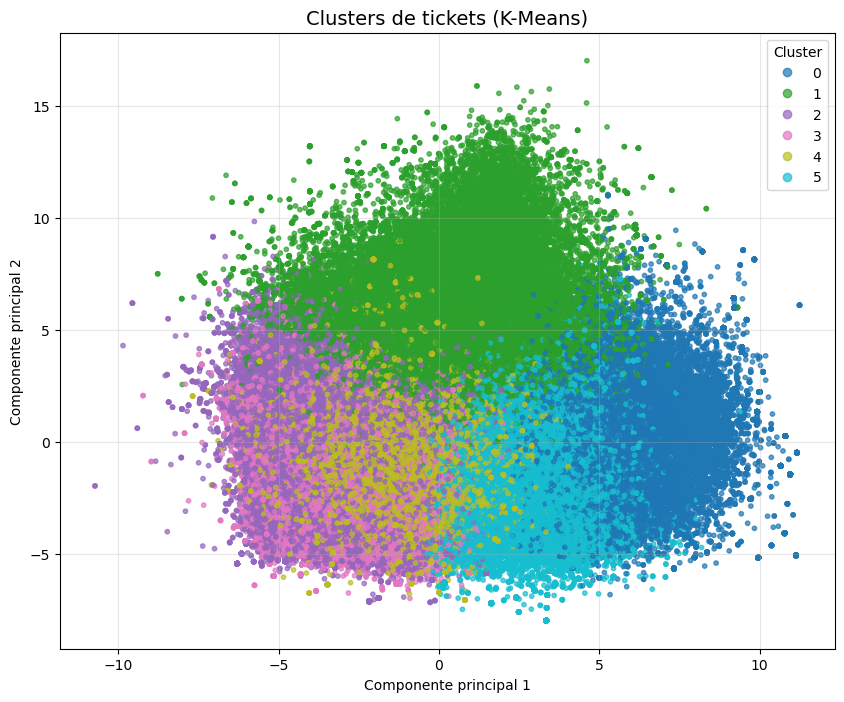

In [ ]:
# Reducir a 2 dimensiones
pca = PCA(n_components=2, random_state=42)
embeddings_2d = pca.fit_transform(embeddings_scaled)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    embeddings_2d[:, 0], embeddings_2d[:, 1],
    c=labels, cmap='tab10', s=10, alpha=0.7
)
plt.title('Clusters de tickets (K-Means)', fontsize=14)
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.grid(True, alpha=0.3)
plt.show()

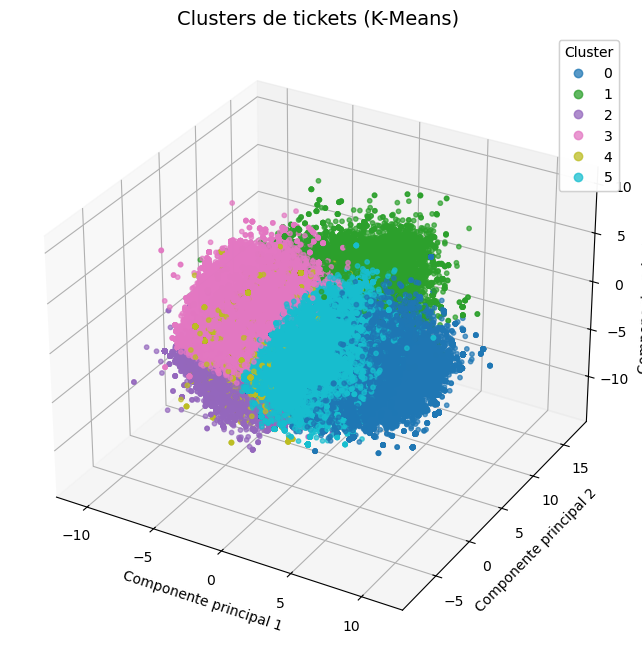

In [ ]:
# Reducir a 3 dimensiones
pca_3d = PCA(n_components=3, random_state=42)
embeddings_3d = pca_3d.fit_transform(embeddings_scaled)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    embeddings_3d[:, 0],
    embeddings_3d[:, 1],
    embeddings_3d[:, 2],
    c=labels,
    cmap='tab10',
    s=10,
    alpha=0.7
)

ax.set_title('Clusters de tickets (K-Means)', fontsize=14)
ax.set_xlabel('Componente principal 1')
ax.set_ylabel('Componente principal 2')
ax.set_zlabel('Componente principal 3')

# Leyenda de clusters
legend = ax.legend(*scatter.legend_elements(), title="Cluster")
ax.add_artist(legend)

plt.show()

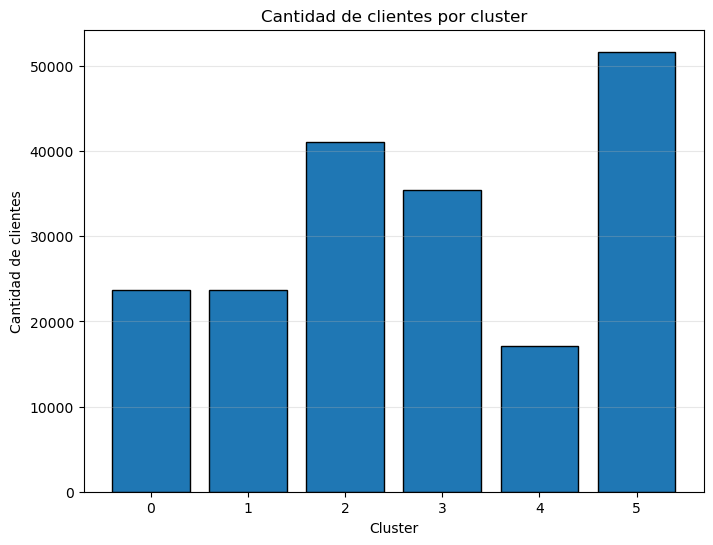

In [ ]:
df_23['TICKET'] = df_23['TICKET'].astype(tickets_clusters['TICKET'].dtype)

# Unir el cluster al dataframe original
df_clustered = df_23.merge(
    tickets_clusters[['TICKET', 'cluster']],
    on='TICKET',
    how='inner'
)
cluster_por_cliente = (
    df_clustered
    .groupby('SOCI_SOCI_ID')['cluster']
    .agg(lambda x: x.value_counts().idxmax())
)

clientes_clusters = cluster_por_cliente.reset_index()
clientes_clusters.columns = ['SOCI_SOCI_ID', 'cluster']

# Conteo de clientes por cluster (sin reordenar)
counts = clientes_clusters['cluster'].value_counts().sort_index()

plt.figure(figsize=(8,6))
plt.bar(counts.index, counts.values, edgecolor='black')
plt.title('Cantidad de clientes por cluster')
plt.xlabel('Cluster')
plt.ylabel('Cantidad de clientes')
plt.grid(axis='y', alpha=0.3)
plt.xticks(counts.index)
plt.show()

In [ ]:
chi = calinski_harabasz_score(embeddings_scaled, labels)
print(f"Calinski–Harabasz Index: {chi:.2f}")


Calinski–Harabasz Index: 35657.73


In [ ]:
k_values = range(3, 12)

chi_scores = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels_k = kmeans.fit_predict(embeddings_scaled)
    chi = calinski_harabasz_score(embeddings_scaled, labels_k)
    chi_scores.append(chi)
    print(f"k={k}: CHI={chi:.2f}")


k=3: CHI=56445.58
k=4: CHI=46403.14
k=5: CHI=40012.82
k=6: CHI=35657.73
k=7: CHI=32414.16
k=8: CHI=29829.63
k=9: CHI=27865.18
k=10: CHI=26193.76
k=11: CHI=24727.25


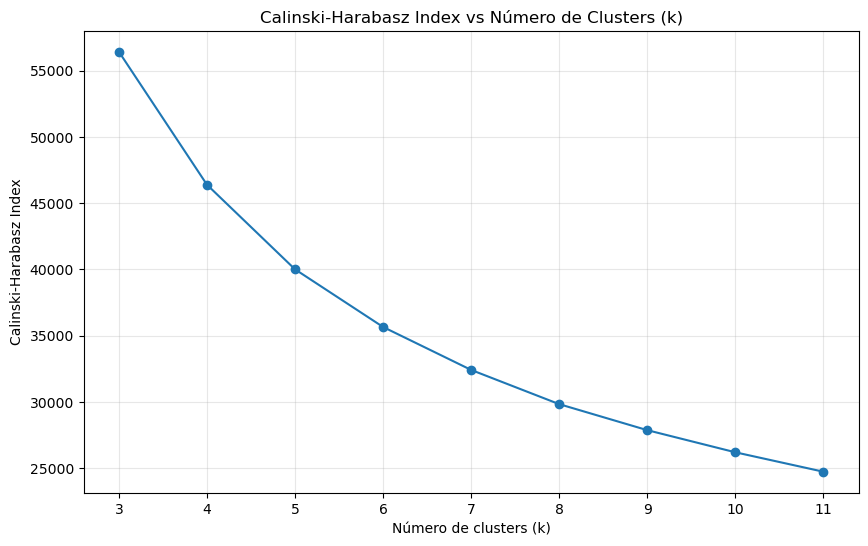

In [ ]:
plt.figure(figsize=(10,6))
plt.plot(k_values, chi_scores, marker='o')
plt.title("Calinski-Harabasz Index vs Número de Clusters (k)")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Calinski-Harabasz Index")
plt.grid(True, alpha=0.3)
plt.show()

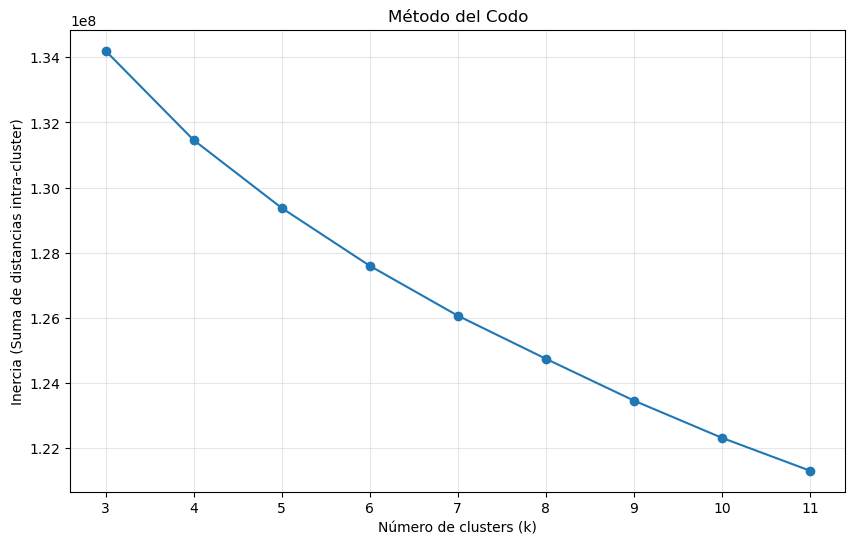

In [ ]:
k_values = range(3, 12)

inertias = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20,
        max_iter=300
    )
    kmeans.fit(embeddings_scaled)
    inertias.append(kmeans.inertia_)

# Graficar
plt.figure(figsize=(10,6))
plt.plot(k_values, inertias, marker='o')
plt.title("Método del Codo")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia (Suma de distancias intra-cluster)")
plt.grid(True, alpha=0.3)
plt.xticks(k_values)
plt.show()

In [ ]:
df_clustered = df_23.merge(tickets_clusters, on='TICKET', how='inner')

In [ ]:
for c in sorted(df_clustered['cluster'].unique()):
    print(f"\n Cluster {c}")
    top_items = (
        df_clustered[df_clustered['cluster'] == c]['CLASS_NAME']
        .value_counts()
        .head(10)
    )
    print(top_items)

In [ ]:
for c in sorted(df_clustered['cluster'].unique()):
    print(f"\n Cluster {c}")
    top_items = (
        df_clustered[df_clustered['cluster'] == c]['SUB_NAME']
        .value_counts()
        .head(10)
    )
    print(top_items)

In [ ]:
df_clustered = df_23.merge(tickets_clusters, on='TICKET', how='inner')

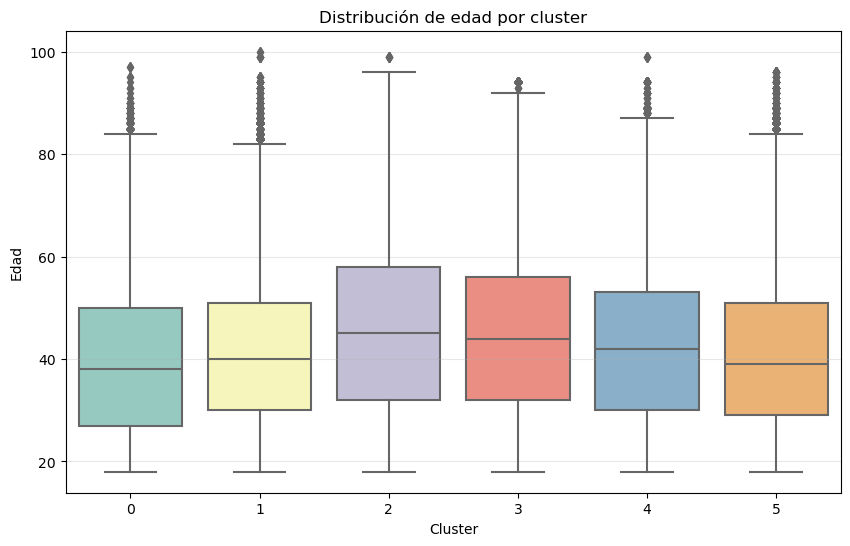

In [ ]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df_clustered, x='cluster', y='SCENTIA_EDAD', palette='Set3')
plt.title('Distribución de edad por cluster')
plt.xlabel('Cluster')
plt.ylabel('Edad')
plt.grid(axis='y', alpha=0.3)
plt.show()

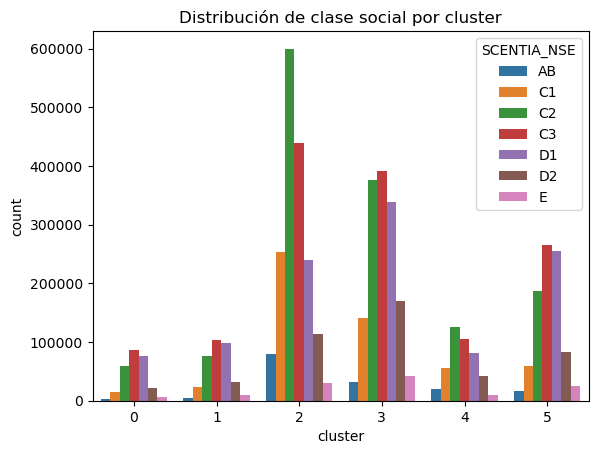

In [ ]:
sns.countplot(
    x='cluster',
    hue='SCENTIA_NSE',
    data=df_clustered,
    hue_order=['AB', 'C1', 'C2', 'C3', 'D1', 'D2', 'E'],
)
plt.title('Distribución de clase social por cluster')
plt.show()

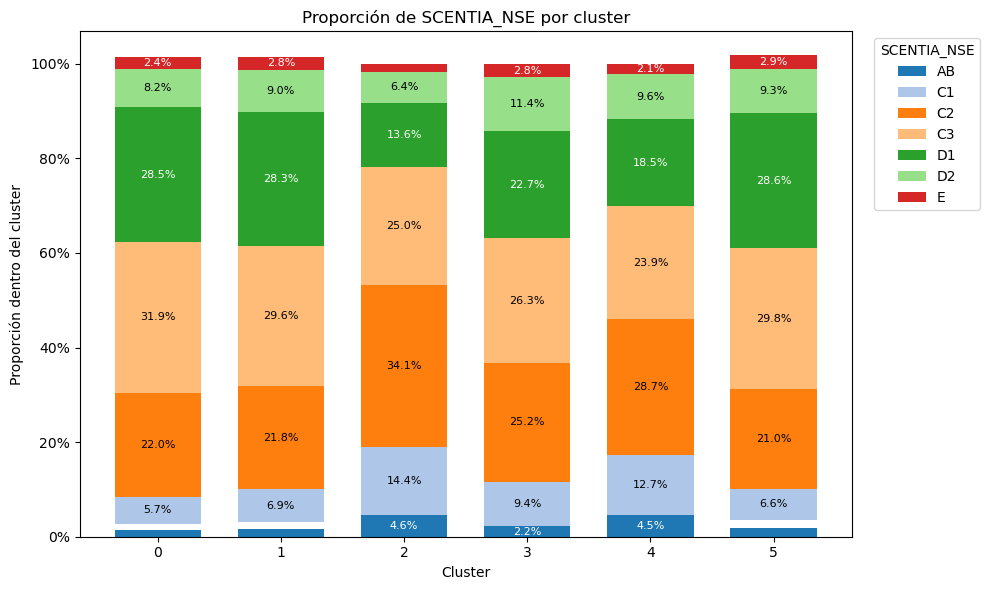

In [ ]:
cols_order = ['AB', 'C1', 'C2', 'C3', 'D1', 'D2', 'E']

# Tabla de conteos y proporciones dentro de cada cluster
counts = pd.crosstab(df_clustered['cluster'], df_clustered['SCENTIA_NSE'])
counts = counts.reindex(columns=cols_order, fill_value=0)
prop = counts.div(counts.sum(axis=1), axis=0).fillna(0)

x = np.arange(len(prop.index))
bar_width = 0.7
cmap = plt.get_cmap('tab20')
colors = [cmap(i) for i in range(len(prop.columns))]

fig, ax = plt.subplots(figsize=(10, 6))
bottom = np.zeros(len(prop.index))

for j, col in enumerate(prop.columns):
    vals = prop[col].values
    ax.bar(x, vals, bar_width, bottom=bottom, label=col, color=colors[j])
    for i, v in enumerate(vals):
        if v <= 0.02:  # omitir segmentos demasiado pequeños (ajustar umbral si se desea)
            bottom[i] += v
            continue
        y = bottom[i] + v / 2
        rgba = colors[j]
        luminance = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
        text_color = 'white' if luminance < 0.5 else 'black'
        ax.text(x[i], y, f"{v*100:.1f}%", ha='center', va='center', color=text_color, fontsize=8)
    bottom += vals

ax.set_xticks(x)
ax.set_xticklabels(prop.index)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylabel('Proporción dentro del cluster')
ax.set_xlabel('Cluster')
ax.set_title('Proporción de SCENTIA_NSE por cluster')
ax.legend(title='SCENTIA_NSE', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

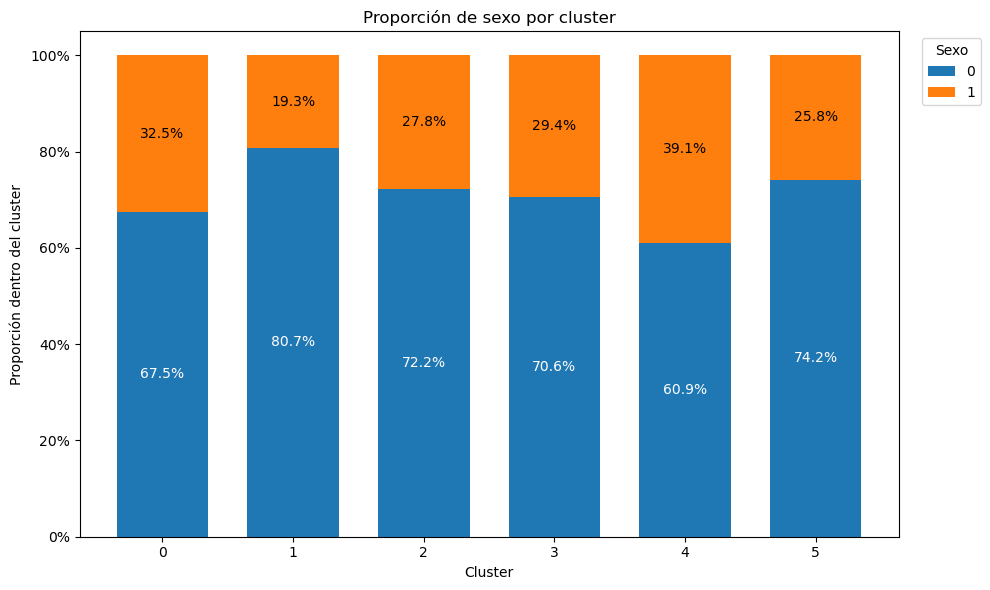

In [ ]:
df_clustered['CLIE_CLIE_SEXO'] = df_clustered['CLIE_CLIE_SEXO'].astype(str)

counts = pd.crosstab(df_clustered['cluster'], df_clustered['CLIE_CLIE_SEXO'])
prop = counts.div(counts.sum(axis=1), axis=0).fillna(0)

x = np.arange(len(prop.index))
bar_width = 0.7
cmap = plt.get_cmap('tab10')
colors = [cmap(i) for i in range(len(prop.columns))]

fig, ax = plt.subplots(figsize=(10, 6))
bottom = np.zeros(len(prop.index))

for j, col in enumerate(prop.columns):
    vals = prop[col].values
    ax.bar(x, vals, bar_width, bottom=bottom, label=col, color=colors[j])
    for i, v in enumerate(vals):
        if v <= 0.02:
            bottom[i] += v
            continue
        y = bottom[i] + v / 2
        rgba = colors[j]
        luminance = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
        text_color = 'white' if luminance < 0.5 else 'black'
        ax.text(x[i], y, f"{v*100:.1f}%", ha='center', va='center', color=text_color, fontsize=10)
    bottom += vals

ax.set_xticks(x)
ax.set_xticklabels(prop.index)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylabel('Proporción dentro del cluster')
ax.set_xlabel('Cluster')
ax.set_title('Proporción de sexo por cluster')
ax.legend(title='Sexo', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
df_23 = df_23.merge(
    tickets_clusters[['TICKET', 'cluster']],
    on='TICKET',
    how='left'
)

df_23.head()

In [ ]:
df_23.describe(include="all")

In [ ]:
ticket_vecs_df = pd.DataFrame(
    np.vstack(tickets_clusters['vector']),
    columns=[f'dim_{i}' for i in range(len(tickets_clusters['vector'][0]))]
)
ticket_vecs_df['TICKET'] = tickets_clusters['TICKET'].values

# Selección de un ticket de referencia
ticket_ref = ticket_vecs_df['TICKET'].iloc[0]

# Vector del ticket de referencia
v_ref = ticket_vecs_df.loc[ticket_vecs_df['TICKET'] == ticket_ref].drop(columns=['TICKET']).values

# Calcular distancia coseno con todos los demás tickets
distancias = cosine_distances(v_ref, ticket_vecs_df.drop(columns=['TICKET']).values)[0]

# Crear dataframe con las distancias
df_dist = pd.DataFrame({
    'TICKET': ticket_vecs_df['TICKET'],
    'distancia': distancias
}).sort_values('distancia')

# Mostrar los 5 tickets más cercanos
df_similares = df_dist.iloc[1:6]
print("Tickets más similares al ticket", ticket_ref)
print(df_similares)

In [ ]:
tickets_cercanos = df_similares['TICKET'].values
tickets_para_ver = np.append(ticket_ref, tickets_cercanos)

df_23[df_23['TICKET'].isin(tickets_para_ver)].sort_values('TICKET')

In [ ]:
ticket_vecs_df = pd.DataFrame(
    np.vstack(tickets_clusters['vector']),
    columns=[f'dim_{i}' for i in range(len(tickets_clusters['vector'][0]))]
)
ticket_vecs_df['TICKET'] = tickets_clusters['TICKET'].values

ticket_ref = np.random.choice(ticket_vecs_df['TICKET'].values)
print(f"Ticket elegido aleatoriamente: {ticket_ref}")

v_ref = ticket_vecs_df.loc[ticket_vecs_df['TICKET'] == ticket_ref].drop(columns=['TICKET']).values

distancias = cosine_distances(v_ref, ticket_vecs_df.drop(columns=['TICKET']).values)[0]

df_dist = pd.DataFrame({
    'TICKET': ticket_vecs_df['TICKET'],
    'distancia': distancias
}).sort_values('distancia')

df_similares = df_dist.iloc[1:21]
print("Tickets más similares al ticket", ticket_ref)
print(df_similares)

In [ ]:
tickets_cercanos = df_similares['TICKET'].values
tickets_para_ver = np.append(ticket_ref, tickets_cercanos)

df_23[df_23['TICKET'].isin(tickets_para_ver)].sort_values('TICKET')

In [ ]:
df_clusters = df_23.merge(tickets_clusters[['TICKET', 'cluster']], on='TICKET', how='left')

# Artículos por cluster
top_articulos = (
    df_clusters.groupby(['cluster_x', 'ARTC_ARTC_ID'])
    .size()
    .reset_index(name='count')
)

# Top 10 artículos más frecuentes por cluster
top10_por_cluster = (
    top_articulos.groupby('cluster_x', group_keys=False)
    .apply(lambda x: x.nlargest(10, 'count'))
    .reset_index(drop=True)
)

top10_info = top10_por_cluster.merge(
    df_23[['ARTC_ARTC_ID', 'CLASS_NAME', 'SUB_NAME']].drop_duplicates(),
    on='ARTC_ARTC_ID',
    how='left'
)

top10_info = top10_info.sort_values(['cluster_x', 'count'], ascending=[True, False])

# 20 primeros artículos más frecuentes por cluster
top10_info

In [ ]:
df_23.columns


Index(['TICKET', 'ARTC_ARTC_ID', 'TIEM_DIA_ID', 'HORA_HORA_ID',
       'GEOG_LOCL_COD', 'GEOG_LOCL_DESC', 'CLASE', 'CLASS_NAME', 'SUBCLASE',
       'SUB_NAME', 'FOPA_FOPA_ID', 'FOPA_FOPA_DESC', 'VNTA_IMPORTE_CON_IVA',
       'VNTA_UNIDADES', 'SOCI_SOCI_ID', 'CLIE_CLIE_SEXO', 'SCENTIA_EDAD',
       'SCENTIA_NSE', 'ARTC_OFN1_ID', 'ARTC_OFN2_ID', 'ARTC_OFN3_ID',
       'ARTC_COMB_ID', 'FECHA', 'MES', 'cluster'],
      dtype='object')


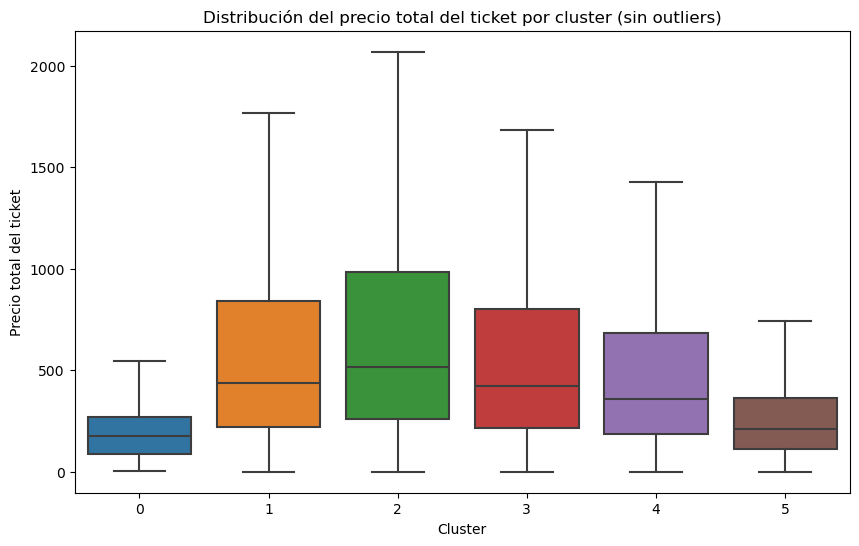

In [ ]:
# Precio total por ticket
precios_por_ticket = df_23.groupby('TICKET')['VNTA_IMPORTE_CON_IVA'].sum().reset_index(name='precio_ticket')

precios_clusters = precios_por_ticket.merge(tickets_clusters[['TICKET', 'cluster']], on='TICKET', how='left')

# Distribución de precios por cluster
plt.figure(figsize=(10,6))
sns.boxplot(x='cluster', y='precio_ticket', data=precios_clusters, showfliers=False)
plt.title('Distribución del precio total del ticket por cluster (sin outliers)')
plt.xlabel('Cluster')
plt.ylabel('Precio total del ticket')
plt.show()

In [ ]:
stats_precios = (
    precios_clusters.groupby('cluster')['precio_ticket']
    .agg(['mean', 'var', 'count'])
    .rename(columns={'mean': 'media_precio', 'var': 'varianza_precio'})
    .reset_index()
)

print(stats_precios)


   cluster  media_precio  varianza_precio   count
0        0    212.543807     33157.852228  123779
1        1    658.963018    514209.269820   93698
2        2    777.847600    764331.832948  285777
3        3    633.923132    504459.650818  249062
4        4    546.744017    372706.070539  130885
5        5    289.840947     83480.431947  268082


In [ ]:
df_clustered = df_23.merge(tickets_clusters[['TICKET', 'cluster']], on='TICKET', how='left')

hora_promedio_cluster = df_clustered.groupby('cluster_x')['HORA_HORA_ID'].mean().reset_index()
hora_promedio_cluster.rename(columns={'HORA_HORA_ID': 'hora_promedio'}, inplace=True)

print(hora_promedio_cluster)


   cluster_x  hora_promedio
0          0      16.270324
1          1      17.360825
2          2      18.025681
3          3      18.063122
4          4      18.857922
5          5      16.775457


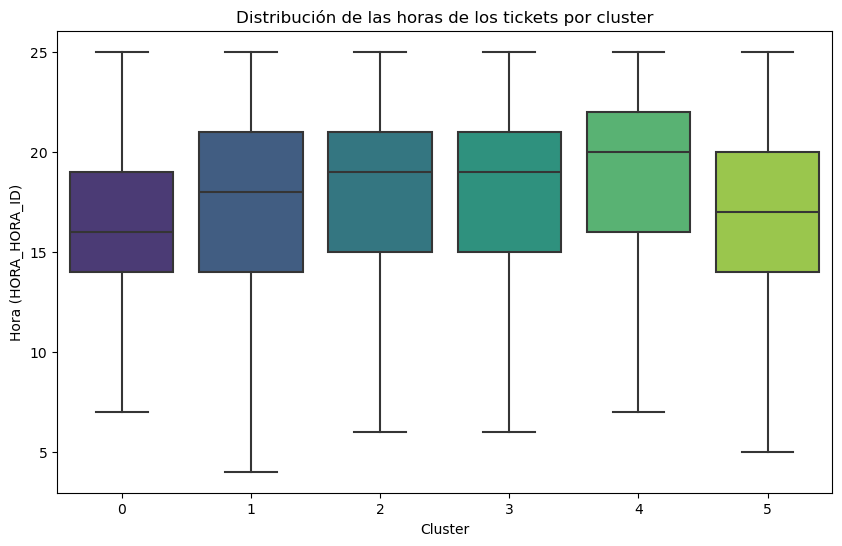

In [ ]:
plt.figure(figsize=(10,6))
sns.boxplot(x='cluster_x', y='HORA_HORA_ID', data=df_clustered, palette='viridis', showfliers=False)
plt.title('Distribución de las horas de los tickets por cluster')
plt.xlabel('Cluster')
plt.ylabel('Hora (HORA_HORA_ID)')
plt.show()

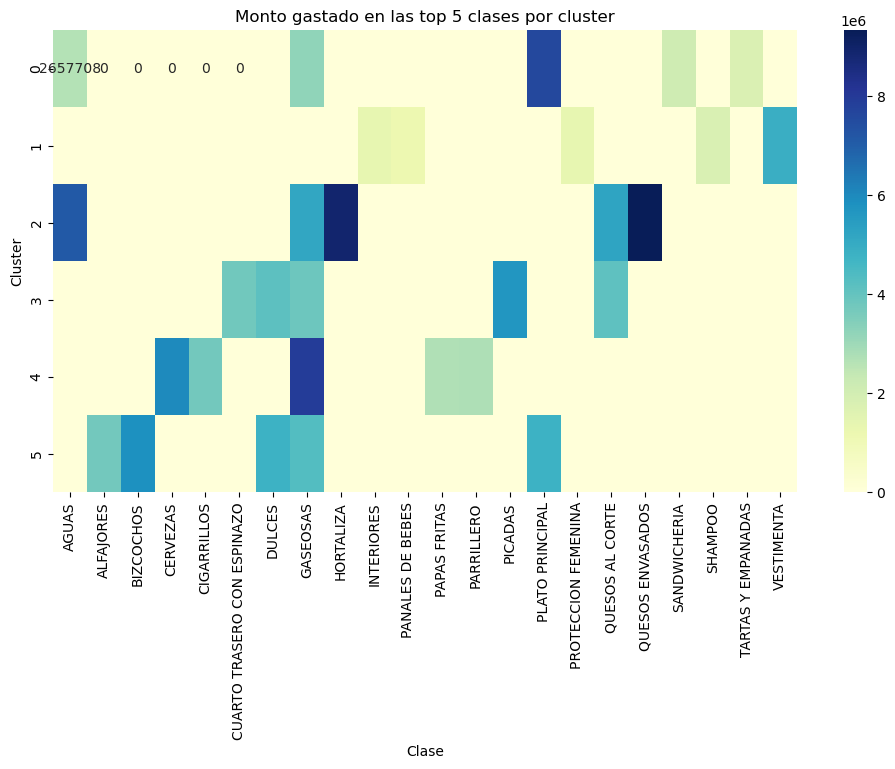

In [ ]:
df_clustered = df_23.merge(tickets_clusters[['TICKET', 'cluster']], on='TICKET', how='left')

# Gasto total por cluster y clase
gasto_cluster_clase = df_clustered.groupby(['cluster_x', 'CLASS_NAME'])['VNTA_IMPORTE_CON_IVA'].sum().reset_index()

# Top 5 clases por cluster
top_clases = gasto_cluster_clase.groupby('cluster_x').apply(lambda x: x.nlargest(5, 'VNTA_IMPORTE_CON_IVA')).reset_index(drop=True)

pivot = top_clases.pivot(index='cluster_x', columns='CLASS_NAME', values='VNTA_IMPORTE_CON_IVA').fillna(0)

plt.figure(figsize=(12,6))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap='YlGnBu')
plt.title('Monto gastado en las top 5 clases por cluster')
plt.xlabel('Clase')
plt.ylabel('Cluster')
plt.show()

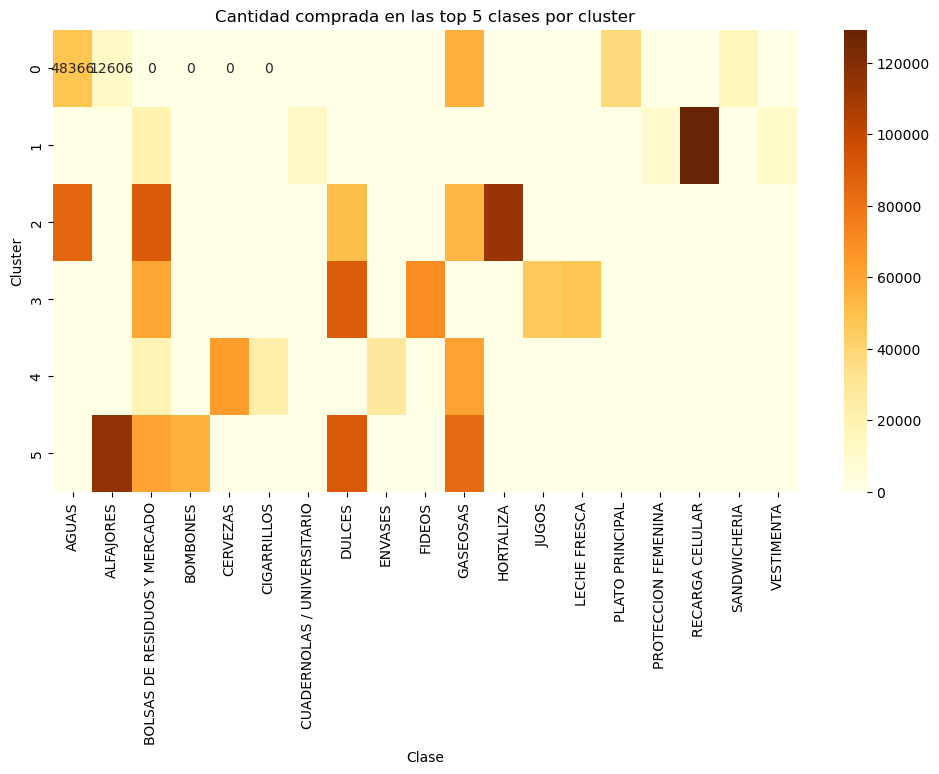

In [ ]:
df_clustered = df_23.merge(tickets_clusters[['TICKET', 'cluster']], on='TICKET', how='left')

# Cantidad total por cluster y clase
cantidad_cluster_clase = df_clustered.groupby(['cluster_x', 'CLASS_NAME'])['VNTA_UNIDADES'].sum().reset_index()

# Top 5 clases por cluster según cantidad comprada
top_clases_cantidad = cantidad_cluster_clase.groupby('cluster_x').apply(lambda x: x.nlargest(5, 'VNTA_UNIDADES')).reset_index(drop=True)

pivot_cantidad = top_clases_cantidad.pivot(index='cluster_x', columns='CLASS_NAME', values='VNTA_UNIDADES').fillna(0)

plt.figure(figsize=(12,6))
sns.heatmap(pivot_cantidad, annot=True, fmt=".0f", cmap='YlOrBr')
plt.title('Cantidad comprada en las top 5 clases por cluster')
plt.xlabel('Clase')
plt.ylabel('Cluster')
plt.show()

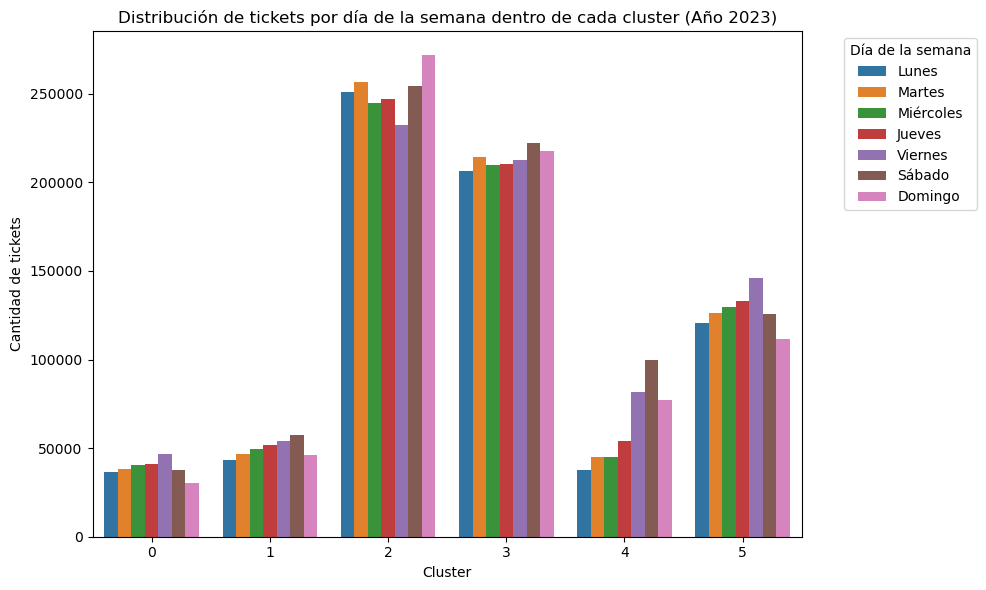

In [ ]:
df_clusters['FECHA'] = pd.to_datetime(df_clusters['FECHA'], errors='coerce')

# Crear columna con el día de la semana
dias_map = {0: 'Lunes', 1: 'Martes', 2: 'Miércoles', 3: 'Jueves', 
            4: 'Viernes', 5: 'Sábado', 6: 'Domingo'}
df_clusters['dia_semana'] = df_clusters['FECHA'].dt.dayofweek.map(dias_map)
orden_dias = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']

plt.figure(figsize=(10,6))
sns.countplot(
    data=df_clusters,
    x='cluster_x',
    hue='dia_semana',
    order=sorted(df_clusters['cluster_x'].unique()),  # orden numérico de clusters
    hue_order=orden_dias
)

plt.title('Distribución de tickets por día de la semana dentro de cada cluster (Año 2023)')
plt.xlabel('Cluster')
plt.ylabel('Cantidad de tickets')
plt.legend(title='Día de la semana', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# ANÁLISIS DE CLIENTES FRECUENTES

In [ ]:
tickets_unicos = df_23[["SOCI_SOCI_ID", "TICKET"]].drop_duplicates()

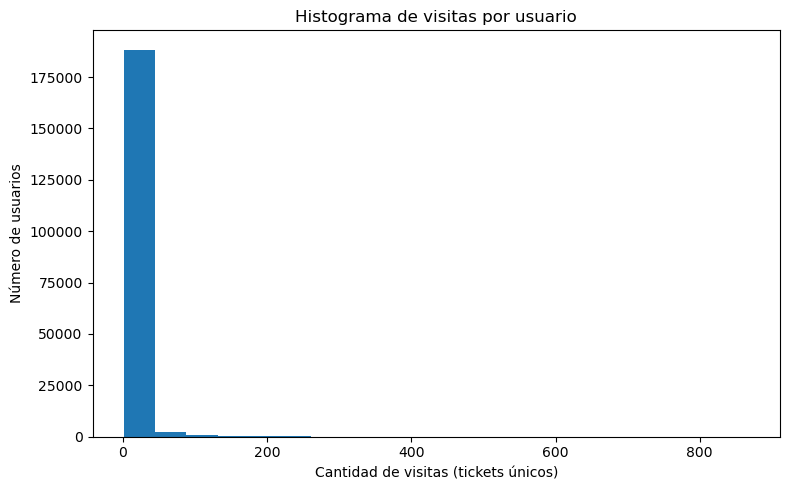

In [ ]:
visitas = tickets_unicos["SOCI_SOCI_ID"].value_counts()

plt.figure(figsize=(8,5))
plt.hist(visitas, bins=20)   # podés ajustar bins
plt.xlabel("Cantidad de visitas (tickets únicos)")
plt.ylabel("Número de usuarios")
plt.title("Histograma de visitas por usuario")
plt.tight_layout()
plt.show()

In [ ]:
usuarios_12 = visitas[visitas >= 12].index

df_23_mas_12 = df_23[df_23["SOCI_SOCI_ID"].isin(usuarios_12)]

In [ ]:
df_23_mas_12.describe(include="all")

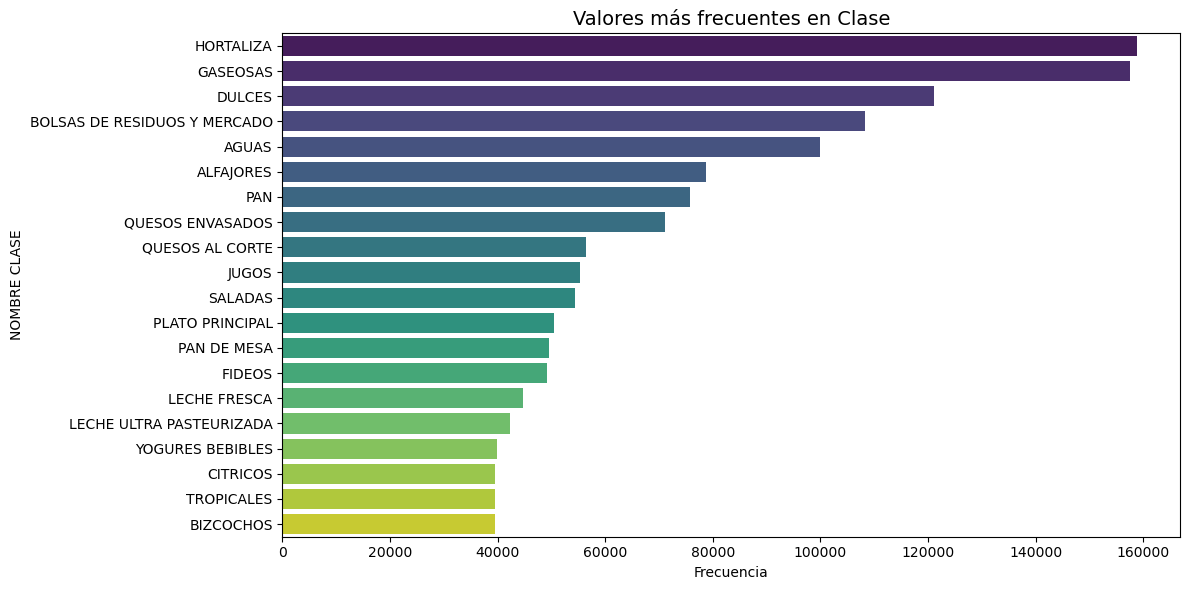

In [ ]:
top_classes = df_23_mas_12["CLASS_NAME"].value_counts().head(20)

plt.figure(figsize=(12,6))
sns.barplot(x=top_classes.values, y=top_classes.index, palette="viridis")

plt.title("Valores más frecuentes en Clase", fontsize=14)
plt.xlabel("Frecuencia")
plt.ylabel("NOMBRE CLASE")
plt.tight_layout()
plt.show()

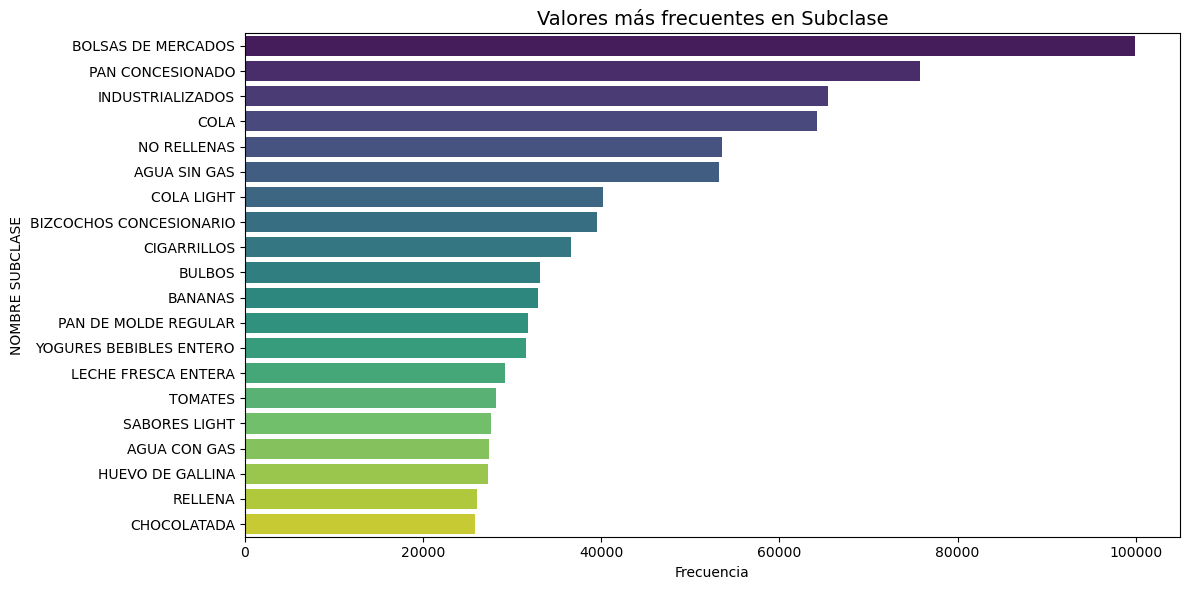

In [ ]:
top_subclasses = df_23_mas_12["SUB_NAME"].value_counts().head(20)

plt.figure(figsize=(12,6))
sns.barplot(x=top_subclasses.values, y=top_subclasses.index, palette="viridis")

plt.title("Valores más frecuentes en Subclase", fontsize=14)
plt.xlabel("Frecuencia")
plt.ylabel("NOMBRE SUBCLASE")
plt.tight_layout()
plt.show()

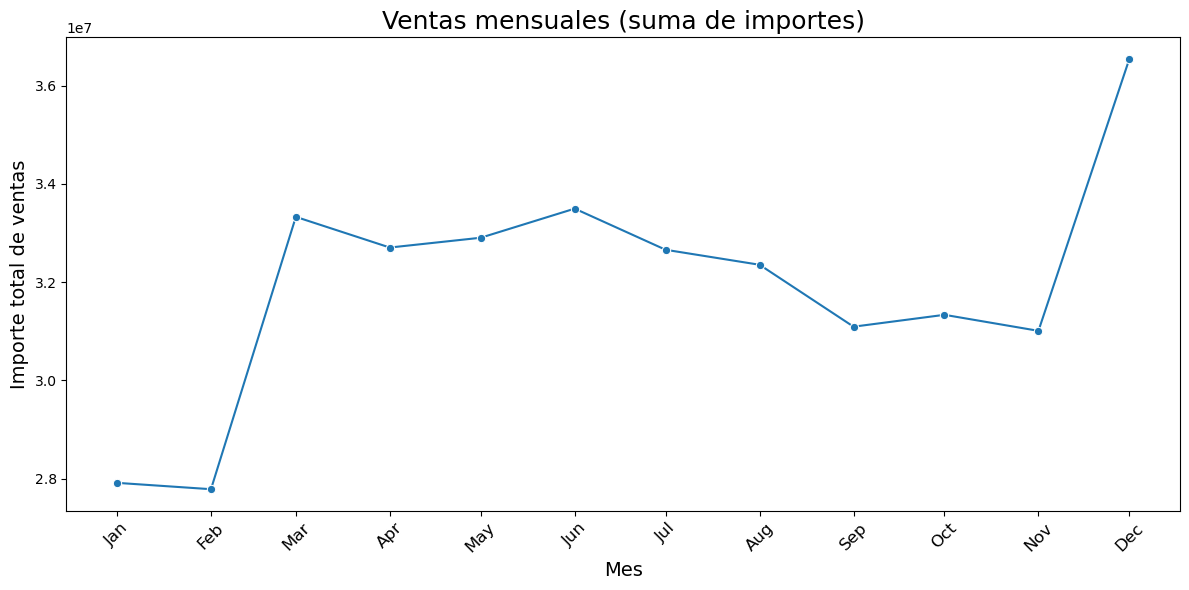

In [ ]:
df_23_mas_12["FECHA"] = pd.to_datetime(df_23_mas_12["TIEM_DIA_ID"])

ventas_mensuales = (
    df_23_mas_12
    .groupby(df_23_mas_12["FECHA"].dt.to_period("M"))["VNTA_IMPORTE_CON_IVA"]
    .sum()
    .reset_index()
)

ventas_mensuales["FECHA"] = ventas_mensuales["FECHA"].dt.to_timestamp()

todos_los_meses = pd.date_range("2023-01-01", "2023-12-01", freq="MS")
ventas_mensuales = (
    ventas_mensuales
    .set_index("FECHA")
    .reindex(todos_los_meses, fill_value=0)
    .reset_index()
    .rename(columns={"index": "FECHA"})
)

plt.figure(figsize=(12,6))
sns.lineplot(x="FECHA", y="VNTA_IMPORTE_CON_IVA", data=ventas_mensuales, marker="o")
plt.title("Ventas mensuales (suma de importes)", fontsize=18)
plt.xlabel("Mes", fontsize=14)
plt.ylabel("Importe total de ventas", fontsize=14)
plt.xticks(todos_los_meses, todos_los_meses.strftime("%b"), fontsize = 12, rotation=45)
plt.tight_layout()
plt.show()

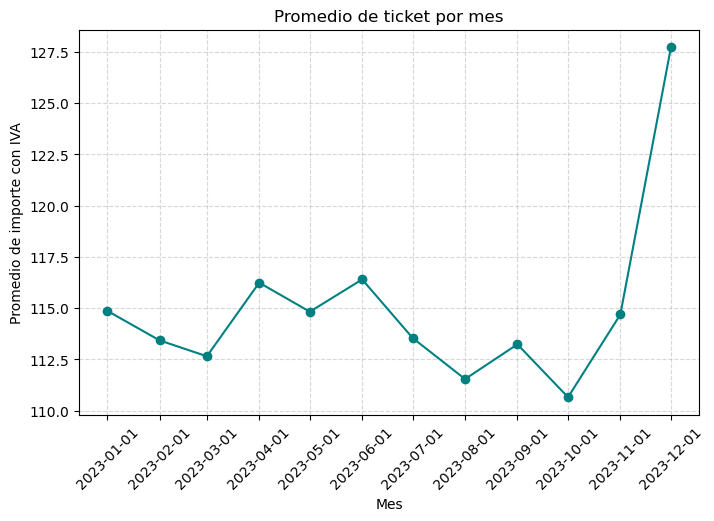

In [ ]:
promedio_mes = (
    df_23_mas_12
    .groupby(df_23_mas_12["TIEM_DIA_ID"].dt.to_period("M"))["VNTA_IMPORTE_CON_IVA"]
    .mean()
    .reindex(pd.period_range(df_23_mas_12["TIEM_DIA_ID"].dt.to_period("M").min(),
                             df_23_mas_12["TIEM_DIA_ID"].dt.to_period("M").max()), fill_value=0)
)

plt.figure(figsize=(8,5))
promedio_mes.index = promedio_mes.index.to_timestamp()  # Para que matplotlib lo entienda como fechas
plt.plot(promedio_mes.index, promedio_mes.values, marker="o", linestyle="-", color="teal")

plt.title("Promedio de ticket por mes")
plt.xlabel("Mes")
plt.ylabel("Promedio de importe con IVA")
plt.xticks(pd.date_range(promedio_mes.index.min(), promedio_mes.index.max(), freq="MS"),
           rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

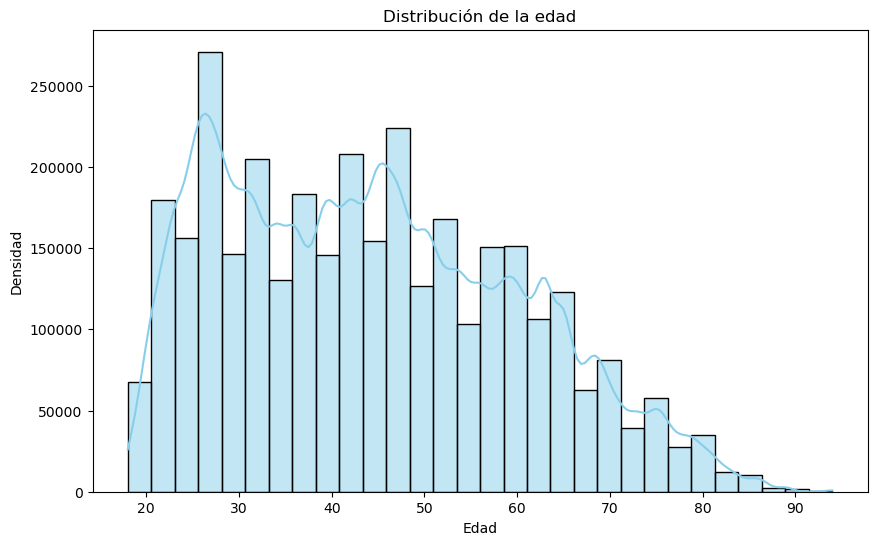

In [ ]:
plt.figure(figsize=(10,6))
sns.histplot(df_23_mas_12["SCENTIA_EDAD"], bins=30, kde=True, color="skyblue")

plt.title("Distribución de la edad")
plt.xlabel("Edad")
plt.ylabel("Densidad")
plt.show()

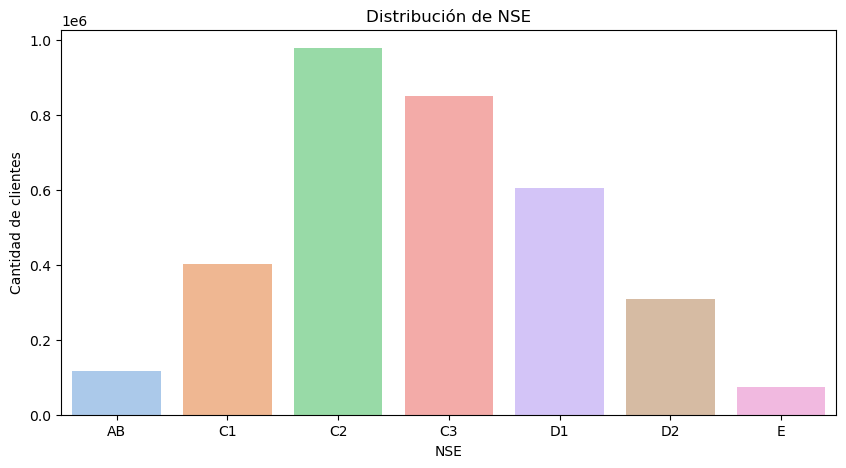

In [ ]:
orden_nse = ["AB", "C1", "C2", "C3", "D1", "D2", "E"]

plt.figure(figsize=(10,5))
sns.countplot(x="SCENTIA_NSE", data=df_23_mas_12, order=orden_nse, palette="pastel")

plt.title("Distribución de NSE")
plt.xlabel("NSE")
plt.ylabel("Cantidad de clientes")
plt.show()

In [ ]:
ventas_totales = df_23["VNTA_IMPORTE_CON_IVA"].sum()
ventas_frecuentes = df_23_mas_12["VNTA_IMPORTE_CON_IVA"].sum()

indice = ventas_frecuentes / ventas_totales

print("Ventas totales:", ventas_totales)
print("Ventas frecuentes:", ventas_frecuentes)
print("Índice:", indice * 100, "%")

In [ ]:
tickets_totales = df_23["TICKET"].nunique()
tickets_frecuentes = df_23_mas_12["TICKET"].nunique()

indice_tickets = tickets_frecuentes / tickets_totales

print("Tickets totales:", tickets_totales)
print("Tickets frecuentes:", tickets_frecuentes)
print("Índice de tickets frecuentes:", indice_tickets * 100, "%")


Tickets totales: 1151283
Tickets frecuentes: 723688
Índice de tickets frecuentes: 62.85926223178836 %


In [ ]:
total_clientes = df_23["SOCI_SOCI_ID"].nunique()
clientes_frecuentes = len(usuarios_12)

porcentaje_clientes = clientes_frecuentes / total_clientes * 100

print("Total clientes únicos:", total_clientes)
print("Clientes frecuentes:", clientes_frecuentes)
print("Porcentaje:", porcentaje_clientes, "%")


Total clientes únicos: 192576
Clientes frecuentes: 16409
Porcentaje: 8.520791791292789 %


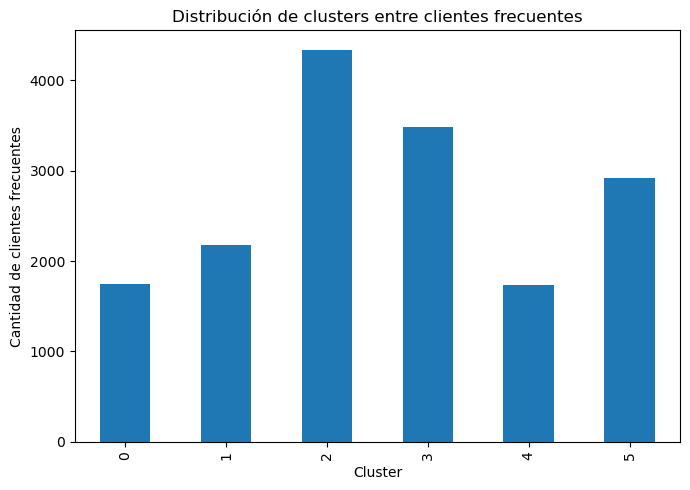

In [ ]:
clientes_clusters = (
    df_23_mas_12[["SOCI_SOCI_ID", "cluster"]]
    .drop_duplicates(subset="SOCI_SOCI_ID")
)
clientes_clusters["cluster"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(7,5),
    title="Distribución de clusters entre clientes frecuentes"
)

plt.xlabel("Cluster")
plt.ylabel("Cantidad de clientes frecuentes")
plt.tight_layout()
plt.show()

In [ ]:
totales = (
    df_23[["SOCI_SOCI_ID", "cluster"]]
    .drop_duplicates(subset="SOCI_SOCI_ID")
    .groupby("cluster")["SOCI_SOCI_ID"]
    .count()
    .rename("clientes_totales")
)

frecuentes = (
    df_23_mas_12[["SOCI_SOCI_ID", "cluster"]]
    .drop_duplicates(subset="SOCI_SOCI_ID")
    .groupby("cluster")["SOCI_SOCI_ID"]
    .count()
    .rename("clientes_frecuentes")
)

tabla = pd.concat([totales, frecuentes], axis=1).fillna(0)
tabla["porcentaje"] = (tabla["clientes_frecuentes"] / tabla["clientes_totales"]) * 100

print(tabla)


         clientes_totales  clientes_frecuentes  porcentaje
cluster                                                   
0                   29073                 1745    6.002133
1                   30135                 2180    7.234113
2                   35378                 4337   12.259031
3                   29587                 3487   11.785582
4                   19929                 1736    8.710924
5                   48474                 2924    6.032100


# POR QUÉ K = 6?

In [ ]:
# Crear variable proxy: número de productos por ticket
productos_por_ticket = df_23.groupby('TICKET')['ARTC_ARTC_ID'].count().rename('n_items')
ticket_meta = productos_por_ticket.reset_index()

# Crear bins para estratificar
ticket_meta['n_items_bin'] = pd.qcut(ticket_meta['n_items'], q=10, duplicates='drop').astype(str)

mes_por_ticket = df_23.groupby('TICKET')['MES'].first().rename('MES')
ticket_meta = ticket_meta.merge(mes_por_ticket.reset_index(), on='TICKET', how='left')
ticket_meta['strata'] = ticket_meta['n_items_bin'] + "_" + ticket_meta['MES'].astype(str)

# Muestreo estratificado en nivel ticket
sample_frac = 0.25  # 25%
n_sample = int(len(ticket_meta) * sample_frac)

sss = StratifiedShuffleSplit(n_splits=1, train_size=n_sample, random_state=42)
strata_labels = ticket_meta['strata'].values
idx_train, _ = next(sss.split(ticket_meta, strata_labels))
sample_ticket_ids = ticket_meta.iloc[idx_train]['TICKET'].values

# df_sample con todas las filas de esos tickets
df_sample = df_23[df_23['TICKET'].isin(sample_ticket_ids)].copy()

In [ ]:
df_sample.head()

In [ ]:
df_sample.describe(include="all")

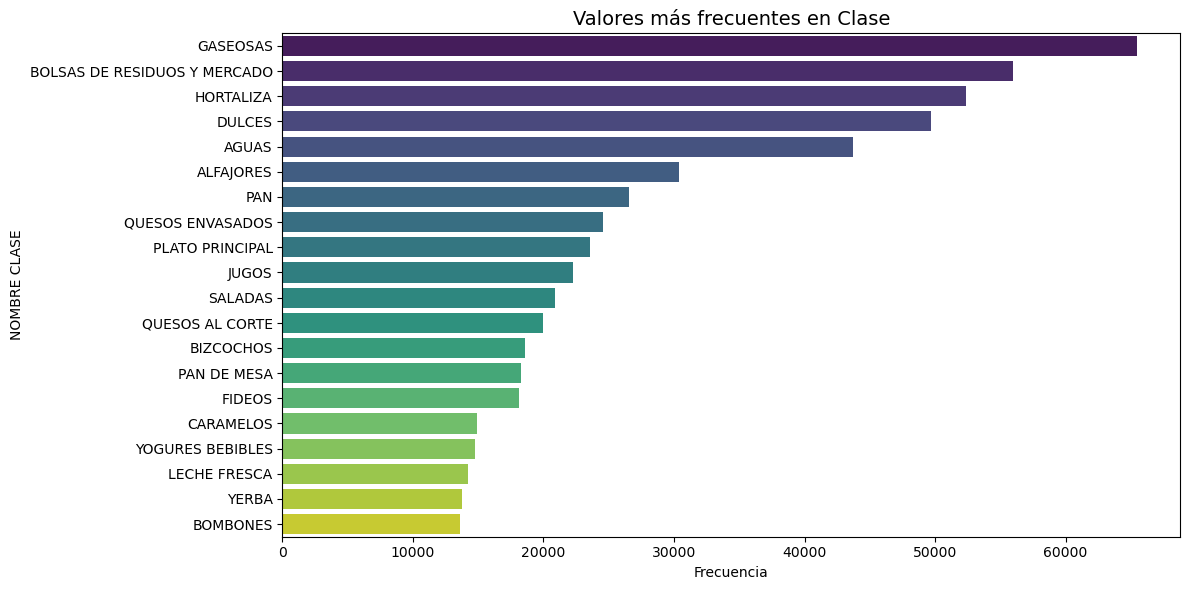

In [ ]:
top_classes = df_sample["CLASS_NAME"].value_counts().head(20)

plt.figure(figsize=(12,6))
sns.barplot(x=top_classes.values, y=top_classes.index, palette="viridis")

plt.title("Valores más frecuentes en Clase", fontsize=14)
plt.xlabel("Frecuencia")
plt.ylabel("NOMBRE CLASE")
plt.tight_layout()
plt.show()

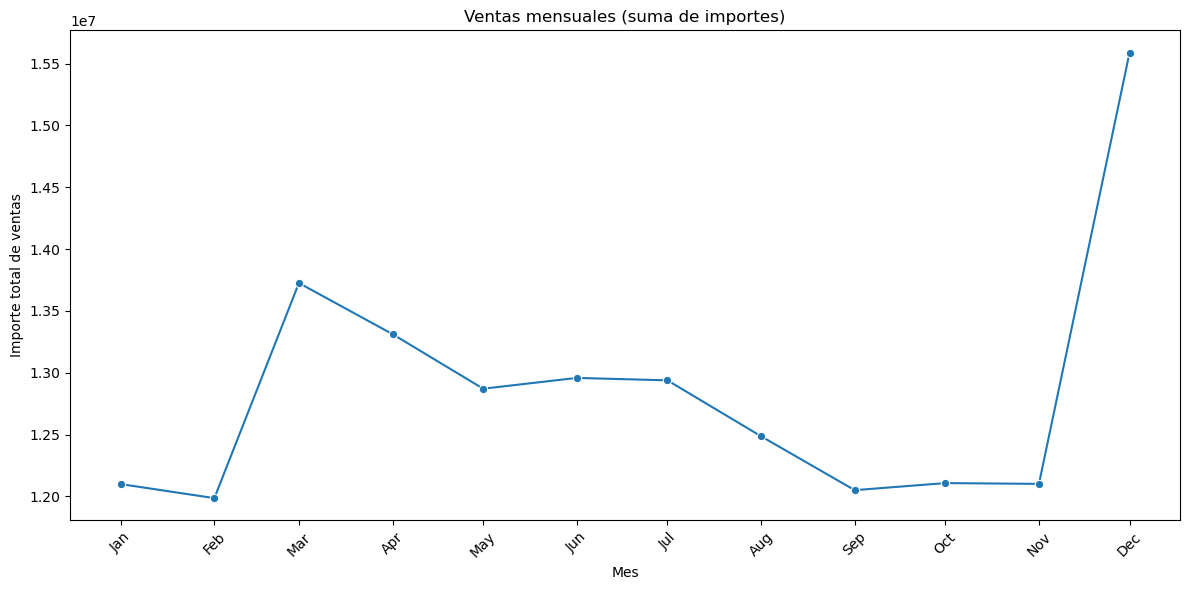

In [ ]:
df_sample["FECHA"] = pd.to_datetime(df_23["TIEM_DIA_ID"])

ventas_mensuales = (
    df_sample
    .groupby(df_sample["FECHA"].dt.to_period("M"))["VNTA_IMPORTE_CON_IVA"]
    .sum()
    .reset_index()
)

ventas_mensuales["FECHA"] = ventas_mensuales["FECHA"].dt.to_timestamp()

todos_los_meses = pd.date_range("2023-01-01", "2023-12-01", freq="MS")
ventas_mensuales = (
    ventas_mensuales
    .set_index("FECHA")
    .reindex(todos_los_meses, fill_value=0)
    .reset_index()
    .rename(columns={"index": "FECHA"})
)

plt.figure(figsize=(12,6))
sns.lineplot(x="FECHA", y="VNTA_IMPORTE_CON_IVA", data=ventas_mensuales, marker="o")
plt.title("Ventas mensuales (suma de importes)")
plt.xlabel("Mes")
plt.ylabel("Importe total de ventas")
plt.xticks(todos_los_meses, todos_los_meses.strftime("%b"), rotation=45)
plt.tight_layout()
plt.show()

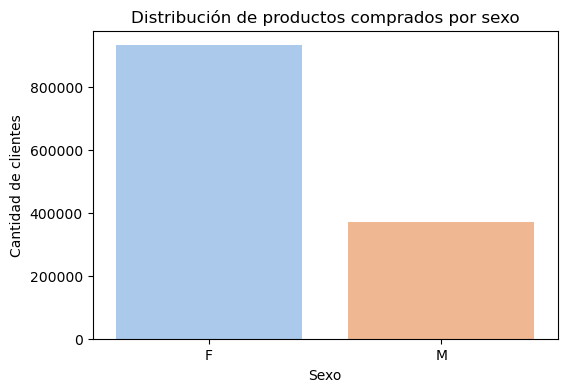

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(
    x="CLIE_CLIE_SEXO",
    data=df_sample,
    palette="pastel",
    order=[0, 1]
)

plt.xticks([0, 1], ["F", "M"])

plt.title("Distribución de productos comprados por sexo")
plt.xlabel("Sexo")
plt.ylabel("Cantidad de clientes")
plt.show()

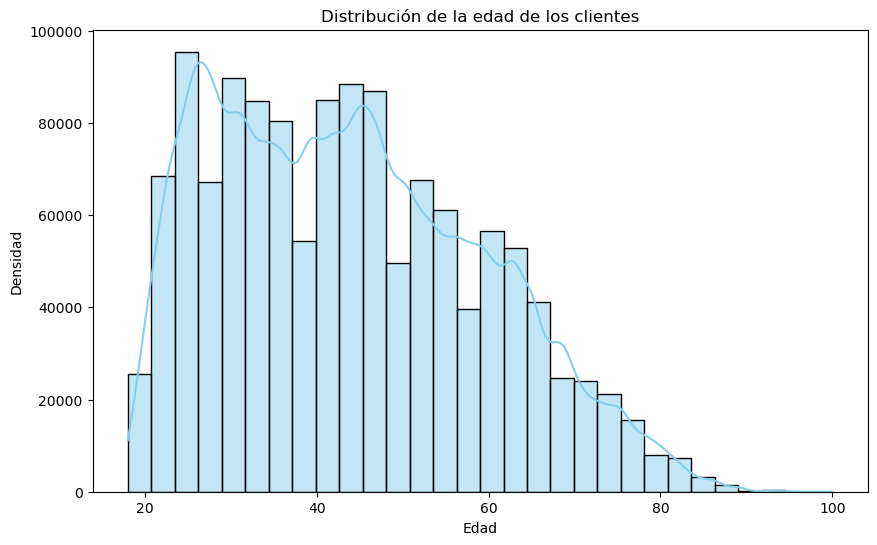

In [ ]:
plt.figure(figsize=(10,6))
sns.histplot(df_sample["SCENTIA_EDAD"], bins=30, kde=True, color="skyblue")

plt.title("Distribución de la edad de los clientes")
plt.xlabel("Edad")
plt.ylabel("Densidad")
plt.show()

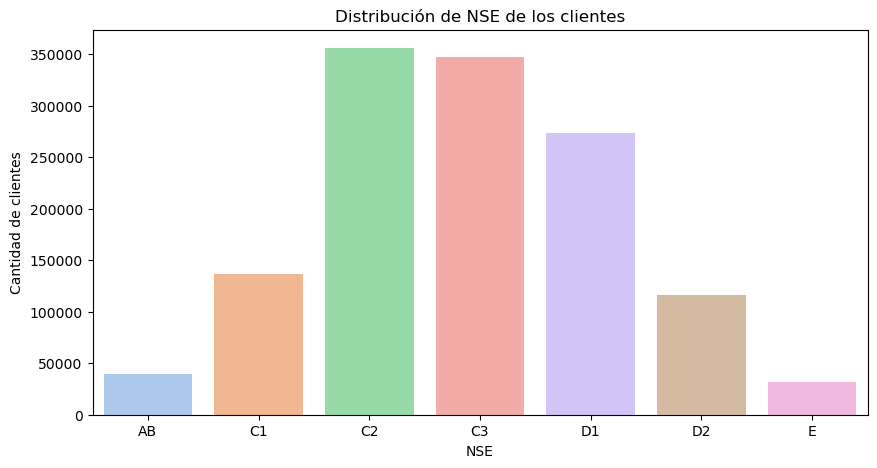

In [ ]:
orden_nse = ["AB", "C1", "C2", "C3", "D1", "D2", "E"]

plt.figure(figsize=(10,5))
sns.countplot(x="SCENTIA_NSE", data=df_sample, order=orden_nse, palette="pastel")

plt.title("Distribución de NSE de los clientes")
plt.xlabel("NSE")
plt.ylabel("Cantidad de clientes")
plt.show()

In [ ]:
df_sample['ARTC_ARTC_ID'] = df_sample['ARTC_ARTC_ID'].astype(str)

tickets = df_sample.groupby('TICKET')['ARTC_ARTC_ID'].apply(list).tolist()
ticket_ids = df_sample['TICKET'].unique().tolist()

print(f"Número de tickets en la muestra: {len(tickets)}")


Número de tickets en la muestra: 287820


In [ ]:
w2v_size = 64
w2v_window = 40
w2v_min_count = 1
w2v_workers = 4
w2v_epochs = 10

w2v_model = Word2Vec(
    sentences=tickets,
    vector_size=w2v_size,
    window=w2v_window,
    min_count=w2v_min_count,
    sg=1,
    workers=w2v_workers,
    epochs=w2v_epochs
)

In [ ]:
# Crear vectores promedio por ticket
# Promediamos los embeddings de los artículos dentro de cada ticket → obtenemos un vector por ticket.
ticket_vecs = []
valid_ids = []

for t_id, items in df_sample.groupby('TICKET')['ARTC_ARTC_ID']:
    valid_vecs = [w2v_model.wv[i] for i in items if i in w2v_model.wv]
    if len(valid_vecs) > 0:
        ticket_vecs.append(np.mean(valid_vecs, axis=0))
        valid_ids.append(t_id)

embeddings = np.vstack(ticket_vecs)
print("Shape de embeddings:", embeddings.shape)


Shape de embeddings: (287820, 64)


In [ ]:
# Estandarizar los embeddings
scaler = StandardScaler()
X_scaled = scaler.fit_transform(embeddings)

In [ ]:
# Definir y entrenar el autoencoder
input_dim = X_scaled.shape[1]
encoding_dim = 16  # compresión fuerte, podés ajustar (8, 16, 32)

input_layer = layers.Input(shape=(input_dim,))
encoded = layers.Dense(32, activation='relu')(input_layer)
encoded = layers.Dense(encoding_dim, activation='relu')(encoded)
decoded = layers.Dense(32, activation='relu')(encoded)
decoded = layers.Dense(input_dim, activation='linear')(decoded)

autoencoder = models.Model(input_layer, decoded)
autoencoder.compile(optimizer='adam', loss='mse')

autoencoder.summary()

In [ ]:
history = autoencoder.fit(
    X_scaled, X_scaled,
    epochs=20,
    batch_size=256,
    shuffle=True,
    validation_split=0.1,
    verbose=1
)

In [ ]:
encoder = models.Model(inputs=input_layer, outputs=encoded)
X_encoded = encoder.predict(X_scaled)

print("Shape de embeddings comprimidos:", X_encoded.shape)


8995/8995 ━━━━━━━━━━━━━━━━━━━━ 12s 1ms/step
Shape de embeddings comprimidos: (287820, 16)


In [ ]:
df_autoencoded = pd.DataFrame(X_encoded, index=valid_ids)
df_autoencoded.reset_index(inplace=True)
df_autoencoded.rename(columns={'index': 'TICKET'}, inplace=True)

df_autoencoded.head()

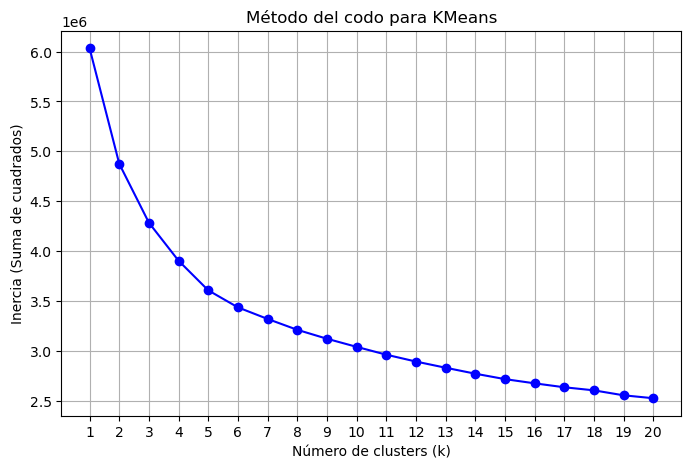

In [ ]:
# Aplico kmeans
# Rango de k que queremos probar
k_range = range(1, 21)

inertia_list = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_encoded)
    inertia_list.append(kmeans.inertia_)

# Graficar el codo
plt.figure(figsize=(8,5))
plt.plot(k_range, inertia_list, 'o-', color='blue')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inercia (Suma de cuadrados)')
plt.title('Método del codo para KMeans')
plt.xticks(k_range)
plt.grid(True)
plt.show()

In [ ]:
k_optimo = 6

kmeans = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
kmeans.fit(X_encoded)
labels = kmeans.labels_

df_autoencoded['cluster'] = labels

In [ ]:
score = silhouette_score(X_encoded, labels)
print(f"Silhouette Score: {score:.4f}")


Silhouette Score: 0.1189


# ANÁLISIS ESTADÍSTICO

In [ ]:
df = pd.read_csv("data/ventas_diarias.csv")

In [ ]:
df.head()

In [ ]:
df['FECHA'] = df['FECHA'].astype(str)

# Convertir a datetime usando el formato correcto (YYYYMM)
df['fecha'] = pd.to_datetime(df['FECHA'], format='%Y%m')

# Expandir cada mes a todos sus días
df_exp = []
for periodo in df['fecha'].unique():
    dias = pd.date_range(periodo, periodo + pd.offsets.MonthEnd(0), freq='D')
    df_exp.extend(dias)

# Crear DataFrame con fechas expandidas
df_nuevo = pd.DataFrame({'fecha': df_exp})

df_nuevo['fecha_str'] = df_nuevo['fecha'].dt.strftime('%Y%m%d')

print(df_nuevo.head(35))


        fecha fecha_str
0  2021-01-01  20210101
1  2021-01-02  20210102
2  2021-01-03  20210103
3  2021-01-04  20210104
4  2021-01-05  20210105
5  2021-01-06  20210106
6  2021-01-07  20210107
7  2021-01-08  20210108
8  2021-01-09  20210109
9  2021-01-10  20210110
10 2021-01-11  20210111
11 2021-01-12  20210112
12 2021-01-13  20210113
13 2021-01-14  20210114
14 2021-01-15  20210115
15 2021-01-16  20210116
16 2021-01-17  20210117
17 2021-01-18  20210118
18 2021-01-19  20210119
19 2021-01-20  20210120
20 2021-01-21  20210121
21 2021-01-22  20210122
22 2021-01-23  20210123
23 2021-01-24  20210124
24 2021-01-25  20210125
25 2021-01-26  20210126
26 2021-01-27  20210127
27 2021-01-28  20210128
28 2021-01-29  20210129
29 2021-01-30  20210130
30 2021-01-31  20210131
31 2021-02-01  20210201
32 2021-02-02  20210202
33 2021-02-03  20210203
34 2021-02-04  20210204


In [ ]:
df['fecha'] = df_nuevo['fecha']

In [ ]:
df.head()

In [ ]:
df['fecha'] = pd.to_datetime(df['fecha'])
df = df.sort_values('fecha')
df = df.set_index('fecha')

ts = df['CANTIDADVENDIDA'].asfreq('D')

In [ ]:
ts = ts.fillna(0)

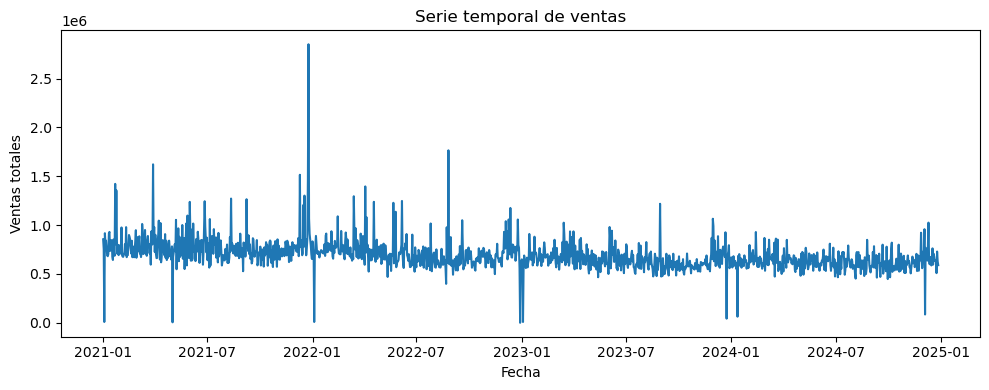

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(ts)
plt.title("Serie temporal de ventas")
plt.xlabel("Fecha")
plt.ylabel("Ventas totales")
plt.tight_layout()
plt.show()

In [ ]:
# Serie sin nulos
y = ts.dropna()

# ADF (Augmented Dickey-Fuller)
adf_result = adfuller(y)
print("ADF statistic:", adf_result[0])
print("ADF p-value:", adf_result[1])


ADF statistic: -4.763724344434701
ADF p-value: 6.377585287287305e-05


ADF:

H0: la serie tiene raíz unitaria (no estacionaria, puede tener tendencia.

p-value bajo (< 0.05): rechazás H0 → serie estacionaria ⇒ sin tendencia fuer
Con un p-valor de 0.00006378 hay evidencia suficiente para rechazar H0 con un nivel de 95% de confianza, por lo que la serie no tiene raíz unitaria, y esto es un indicio de que no tiene tendencia.erencias).

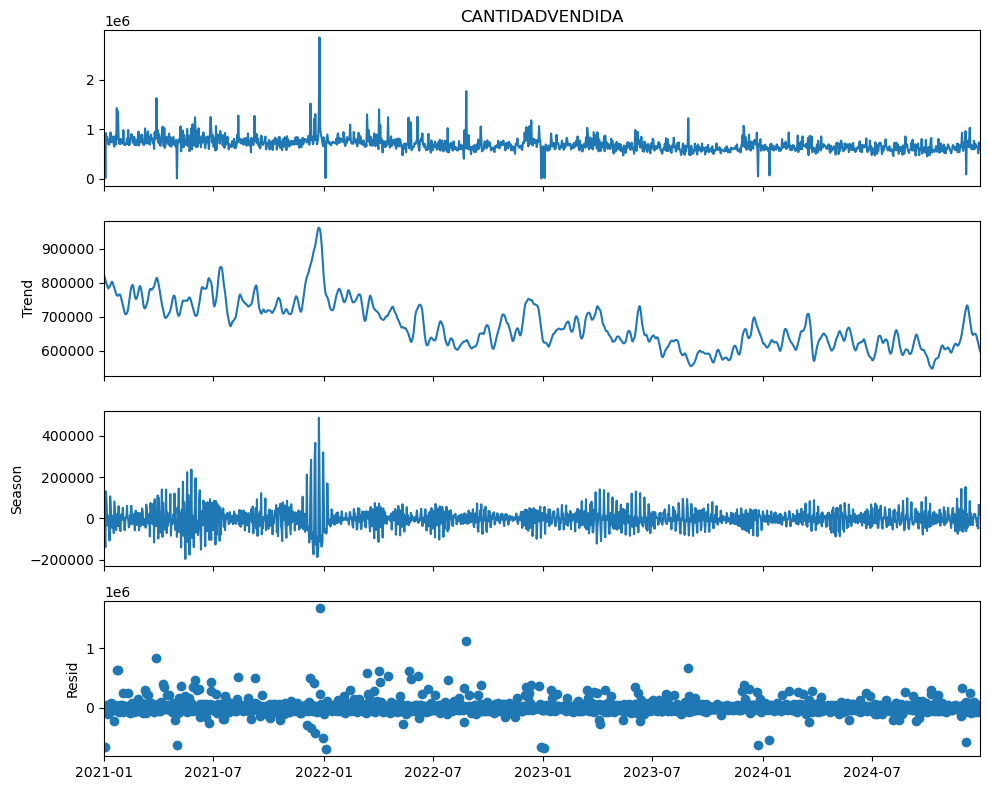

In [ ]:
y = ts.dropna()

stl = STL(y, period=7, robust=True)
result = stl.fit()

# Plot
fig = result.plot()
fig.set_size_inches(10, 8)
plt.tight_layout()
plt.show()

In [ ]:
y = ts.dropna()
stl = STL(y, period=7, robust=True)  # periodo según tu frecuencia
res = stl.fit()

seasonal = res.seasonal
trend = res.trend
resid = res.resid

Hacer un test de que la componente estacional es distinta de cero en promedio

In [ ]:
# H0: la componente estacional tiene media 0 (no estacionalidad sistemática)
t_stat, p_value = stats.ttest_1samp(seasonal, popmean=0)
print(p_value)


0.9979558092521867


No hay evidencia suficiente para rechazar H0 con un 95% de confianza, por lo que no hay estacionalidad en la serie de tiempo.

In [ ]:
df = ts.to_frame(name='ventas')
df['dow'] = df.index.dayofweek  # 0=lunes,...,6=domingo

grupos = [g['ventas'].values for _, g in df.groupby('dow')]

f_stat, p_value = stats.f_oneway(*grupos)
print("p-value ANOVA:", p_value)


p-value ANOVA: 0.6023017550674191


H0: todas las medias son iguales → no hay diferencia sistemática entre días → no estacionalidad semanal fuerte.

Si p\_value es muy bajo → rechazás H0 → evidencia estadística de estacionalidad semanal

No hay evidencia suficiente para rechazar H0 con un 95% de confianza, por lo que no hay estacionalidad semanal fuerte.